# 04 — Lakehouse Compute Benchmark: Executive Summary, Compute Equivalency & TCO

This notebook consolidates telemetry across all **5 compute/storage engine variants** and **4 Medallion stages** defined in `SPEC.md`:

| Variant (`engine_variant`) | Execution Engine | Bronze Storage | Silver / Gold Intermediates |
| :--- | :--- | :--- | :--- |
| `spark_standard` | Dataproc GCE `2.3-debian12` Standard Spark (JVM) | Open GCS Parquet (`gcs_parquet`) | Open GCS Parquet (`gcs_parquet`) |
| `spark_lightning_base` | Dataproc GCE `2.3-debian12` Lightning Engine (`runtime=default`) | Open GCS Parquet (`gcs_parquet`) | Open GCS Parquet (`gcs_parquet`) |
| `spark_lightning_nqe` | Dataproc GCE `2.3-debian12` Lightning Engine + Gluten/Velox C++ (`runtime=native`) | Open GCS Parquet (`gcs_parquet`) | Open GCS Parquet (`gcs_parquet`) |
| `bigframes_biglake_gcs` | BigQuery `BigFrames 2.x` (`ordering_mode="partial"`) over External BigLake | Open GCS Parquet (`biglake_gcs_parquet`) | Native BQ (`DS_SILVER_BQ` / `DS_GOLD_BQ`, `PHYSICAL`) |
| `bigframes_native_bq` | BigQuery `BigFrames 2.x` (`ordering_mode="partial"`) over Native Storage | BigQuery Capacitor (`bq_native_capacitor`, `PHYSICAL`) | Native BQ (`DS_SILVER_BQ` / `DS_GOLD_BQ`, `PHYSICAL`) |

> **Methodology & Timer Boundary Caveats (`SPEC.md` §1 & §3):**
> - **In-Cluster Warm Spark vs. Client-Side `BigFrames` Timers:** Spark (`01`, `02`) starts stage timers *inside* Dataproc after an explicit `spark.range(1).count()` warm-up, capturing pure stage execution + GCS Parquet write I/O (excluding `gcloud` submission, YARN AM startup, and cluster provisioning). `BigFrames` (`03`) records `wall_clock_sec` *client-side* around graph construction + `.to_gbq()`, which includes per-stage REST API / job polling round-trips (~`1–3s` per stage).
> - **Bronze Parity vs. Native BQ Intermediates:** Stage 1 (`stage1_bronze_to_silver`) is the **exact apples-to-apples Parquet storage parity check** (`Spark GCS Parquet` vs. `BigFrames BigLake` over the exact same GCS Parquet files). In Stages 2A, 2B, and 3, both `BigFrames` passes read and materialize native BigQuery tables in `DS_SILVER_BQ` / `DS_GOLD_BQ` (with Stage 3 joining the respective BigLake vs. Native Bronze dimensions).

**Sections:**
1. **Parameterized US Pricing & Analysis Configuration** (single-source `scripts.metrics_helper.US_LIST_RATES` + CUD/Spot/BQ/Storage parameters)
2. **Telemetry Loading, Priority Resolution & Provenance Audit** (`live_runs/` -> `results/` -> offline sample fallback)
3. **Correctness & Checksum Parity Matrix** (`100%` row-count parity & `±0.01%` `checksum_net_paid` assertion)
4. **Stage Latency Breakdown** (Core Relational ELT `1 + 2A + 3` vs Python UDF `2B`)
5. **Execution Timeline Waterfall (Gantt)** (`start_epoch_sec` -> `end_epoch_sec`, normalized to `t=0` per engine)
6. **Empirical Compute Equivalency** (`Provisioned Spark Worker vCPU-s / Consumed BQ Slot-s`, separating Stage 1 vs `1+2A+3`)
7. **Stage 2A Vectorized vs. Stage 2B Python UDF Fallback Analysis** (normalized by `sample_fraction`, NQE JVM fallback diagnostics)
8. **Lightning Engine Surcharge Break-Even & Full Parameterized TCO Matrix** (On-Demand, `15% Primary 1-Yr CUD + 85% Spot EFM`, `1-Yr CUD`, `3-Yr CUD`, cluster-lifetime sensitivity, and Dual BigQuery Billing Lenses)


In [1]:
# ==============================================================================
# 1. PARAMETERIZED US PRICING & BENCHMARK CONFIGURATION
#    Sources base US list rates from scripts.metrics_helper.US_LIST_RATES so
#    all notebooks (01-04) share identical Dataproc and BigQuery list constants.
# ==============================================================================
import importlib.util
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

try:
    from dotenv import load_dotenv
except ImportError:
    load_dotenv = None


def find_repo_root() -> Path:
    """Locate repository root safely whether notebook starts in root, notebooks/, or /tmp."""
    env_root = os.environ.get("LAKEHOUSE_BENCH_ROOT", "").strip()
    if env_root:
        candidate = Path(env_root).expanduser().resolve()
        if (candidate / "SPEC.md").exists():
            return candidate
    cwd = Path.cwd().resolve()
    for candidate in (cwd, cwd.parent, cwd.parent.parent):
        if (candidate / "SPEC.md").exists() and (candidate / "results").exists():
            return candidate
    raise FileNotFoundError("Could not locate repository root containing SPEC.md and results/.")


REPO_ROOT = find_repo_root()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

try:
    from scripts.metrics_helper import US_LIST_RATES, resolve_bench_config
    _env_cfg = resolve_bench_config(repo_root=REPO_ROOT, populate_environ=False)
except Exception:
    US_LIST_RATES = {
        "gce_vcpu_hr_by_family": {"n2d-standard": 0.030972},
        "gce_ram_gb_hr_by_family": {"n2d-standard": 0.004150},
        "dataproc_gce_fee_per_vcpu_hr": 0.010,
        "dataproc_lightning_surcharge_per_vcpu_hr": 0.0025,
        "local_ssd_gb_per_disk": 375.0,
        "local_ssd_usd_per_gb_month": 0.080,
        "hours_per_month": 730.0,
        "bq_enterprise_slot_hr_usd": 0.060,
    }
    _env_cfg = {}

HAS_JINJA2 = importlib.util.find_spec("jinja2") is not None


def show_table(frame: pd.DataFrame, fmt: dict | str | None = None) -> None:
    """Render styled DataFrame when jinja2 is installed; fall back cleanly otherwise."""
    if HAS_JINJA2 and fmt is not None:
        display(frame.style.format(fmt, na_rep="-"))
    else:
        display(frame)


# Visual styling
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
})

# Analysis controls
TARGET_SCALE_PRESET = None   # e.g. "small_1g", "medium_100g", "large_500g"; None -> auto (.env or latest)
TARGET_RUN_ID = None         # Optional explicit run_id filter; None -> latest run per (scale_preset, engine_variant)
PARITY_TOLERANCE_PCT = 0.01  # SPEC.md §3 maximum allowed checksum_net_paid delta (%)
STRICT_PARITY_ASSERT = True  # Fail loudly if any stage exceeds PARITY_TOLERANCE_PCT or row count drifts

# Highlighted Dataproc cluster blend (all 4 blends are evaluated in the full TCO matrix)
ACTIVE_CLUSTER_BLEND = "15% Primary (1-Yr CUD) + 85% Spot Secondary (EFM)"
INCLUDE_MASTER_IN_TCO = True  # True bills master + workers (20 vCPUs); False bills workers only (16 vCPUs)

# Cluster-lifecycle sensitivity parameters (models non-stage overhead for ephemeral Dataproc clusters)
SPARK_CLUSTER_UTILIZATION_SENSITIVITY = 0.70  # e.g. 70% steady-state cluster utilization (30% idle/driver gap)
SPARK_EPHEMERAL_PROVISION_OVERHEAD_SEC = 120.0  # Typical cluster spin-up/teardown amortization when ephemeral

# Derive N2D list & commitment/Spot unit rates from single-source US_LIST_RATES
_od_vcpu = float(US_LIST_RATES["gce_vcpu_hr_by_family"]["n2d-standard"])
_od_ram = float(US_LIST_RATES["gce_ram_gb_hr_by_family"]["n2d-standard"])
_od_ssd = (
    float(US_LIST_RATES["local_ssd_gb_per_disk"])
    * float(US_LIST_RATES["local_ssd_usd_per_gb_month"])
    / float(US_LIST_RATES["hours_per_month"])
)
_bq_paygo = float(US_LIST_RATES["bq_enterprise_slot_hr_usd"])

PRICING_CONFIG = {
    "regions": {
        "dataproc_gce": "us-central1",
        "bigquery_gcs": "US",
    },
    # GCE N2D Standard (us-central1 list & CUD/Spot reference rates, 4 GB RAM per vCPU)
    "gce_n2d_standard": {
        "on_demand": {"vcpu_hr": _od_vcpu,                  "ram_gb_hr": _od_ram,                  "label": "100% On-Demand"},
        "cud_1yr":   {"vcpu_hr": round(_od_vcpu * 0.63, 6), "ram_gb_hr": round(_od_ram * 0.63, 6), "label": "1-Yr Resource CUD (~37% off)"},
        "cud_3yr":   {"vcpu_hr": round(_od_vcpu * 0.45, 6), "ram_gb_hr": round(_od_ram * 0.45, 6), "label": "3-Yr Resource CUD (~55% off)"},
        "spot":      {"vcpu_hr": round(_od_vcpu * 0.35, 6), "ram_gb_hr": round(_od_ram * 0.35, 6), "label": "Spot VM (~65% off list)"},
    },
    # NVMe Local SSD (375 GB partition in us-central1: $0.08/GB-mo / 730 hrs = $0.041096/SSD-hr)
    "local_ssd_375gb_hr": {
        "on_demand": round(_od_ssd, 6),
        "cud_1yr":   round(_od_ssd * 0.63, 6),
        "cud_3yr":   round(_od_ssd * 0.45, 6),
        "spot":      round(_od_ssd * 0.66, 6),
    },
    # Dataproc GCE software & runtime fees (flat per vCPU-hr across cluster vCPUs)
    "dataproc_mgmt_fee_per_vcpu_hr": float(US_LIST_RATES["dataproc_gce_fee_per_vcpu_hr"]),
    "lightning_surcharge_per_vcpu_hr": float(US_LIST_RATES["dataproc_lightning_surcharge_per_vcpu_hr"]),
    # BigQuery Enterprise Edition (US multi-region)
    "bq_enterprise_slot_hr": {
        f"PayGo Autoscale (${_bq_paygo:.2f}/slot-hr)": _bq_paygo,
        f"1-Yr Commit (${_bq_paygo * 0.80:.3f}/slot-hr)": round(_bq_paygo * 0.80, 4),
        f"3-Yr Commit (${_bq_paygo * 0.60:.3f}/slot-hr)": round(_bq_paygo * 0.60, 4),
    },
    "bq_autoscale_min_bill_sec": 60.0,   # Minimum 60s billable window per contiguous autoscale event
    "bq_autoscale_increment_slots": 50,  # Enterprise Edition autoscale step granularity
    # Storage reference rates (US multi-region)
    "storage_monthly_usd": {
        "gcs_standard_per_gb": 0.026,           # GCS Standard US multi-region
        "bq_active_physical_per_gib": 0.040,    # BigQuery Active Physical Storage US multi-region
        "bq_long_term_physical_per_gib": 0.020, # BigQuery Long-Term Physical Storage (90+ days unchanged)
    },
}

# Canonical ordering & human-friendly labels
ENGINE_ORDER = [
    "spark_standard",
    "spark_lightning_base",
    "spark_lightning_nqe",
    "bigframes_biglake_gcs",
    "bigframes_native_bq",
]
ENGINE_LABELS = {
    "spark_standard": "Dataproc Standard Spark",
    "spark_lightning_base": "Dataproc Lightning (Base)",
    "spark_lightning_nqe": "Dataproc Lightning (NQE)",
    "bigframes_biglake_gcs": "BigFrames (BigLake GCS)",
    "bigframes_native_bq": "BigFrames (Native BQ)",
}
ENGINE_PALETTE = {
    "spark_standard": "#5C6BC0",
    "spark_lightning_base": "#26A69A",
    "spark_lightning_nqe": "#00796B",
    "bigframes_biglake_gcs": "#FB8C00",
    "bigframes_native_bq": "#E65100",
}
STAGE_ORDER = [
    "stage1_bronze_to_silver",
    "stage2a_silver_vectorized",
    "stage2b_silver_udf",
    "stage3_silver_to_gold",
]
CORE_RELATIONAL_STAGES = [
    "stage1_bronze_to_silver",
    "stage2a_silver_vectorized",
    "stage3_silver_to_gold",
]
STAGE_LABELS = {
    "stage1_bronze_to_silver": "Stage 1: Bronze -> Silver",
    "stage2a_silver_vectorized": "Stage 2A: Vectorized Tiering",
    "stage2b_silver_udf": "Stage 2B: Python UDF / Pushdown",
    "stage3_silver_to_gold": "Stage 3: 5-Way Join & Rolling Gold",
}
STAGE_SHORT_LABELS = {
    "stage1_bronze_to_silver": "Stage 1\nBronze->Silver",
    "stage2a_silver_vectorized": "Stage 2A\nVectorized",
    "stage2b_silver_udf": "Stage 2B\nPython UDF",
    "stage3_silver_to_gold": "Stage 3\nGold Mart",
    "CORE_RELATIONAL (1+2A+3)": "Core Rel\n(1+2A+3)",
}
STAGE_COLORS = {
    "stage1_bronze_to_silver": "#3949AB",
    "stage2a_silver_vectorized": "#00897B",
    "stage2b_silver_udf": "#D81B60",
    "stage3_silver_to_gold": "#F4511E",
}

print(
    f"Pricing configuration initialized for us-central1 GCE/Dataproc (${_od_vcpu + 4 * _od_ram:.6f}/vCPU-hr N2D compute) "
    f"& US BigQuery Enterprise Edition (${_bq_paygo:.2f}/slot-hr PayGo)."
)


Pricing configuration initialized for us-central1 GCE/Dataproc ($0.047572/vCPU-hr N2D compute) & US BigQuery Enterprise Edition ($0.06/slot-hr PayGo).


In [2]:
# ==============================================================================
# 2. TELEMETRY LOADING, PRIORITY RESOLUTION & PROVENANCE BANNER
# ==============================================================================
import json

env_file = REPO_ROOT / ".env"
if load_dotenv is not None and env_file.exists():
    load_dotenv(env_file, override=False)

# Resolve cluster topology from .env (falling back to SPEC.md / .env.example defaults)
_MACHINE_SPECS = {
    "n2d-standard-2":  (2, 8),
    "n2d-standard-4":  (4, 16),
    "n2d-standard-8":  (8, 32),
    "n2d-standard-16": (16, 64),
    "n2d-standard-32": (32, 128),
}
master_type = os.environ.get("MASTER_MACHINE_TYPE", _env_cfg.get("MASTER_MACHINE_TYPE", "n2d-standard-4"))
worker_type = os.environ.get("WORKER_MACHINE_TYPE", _env_cfg.get("WORKER_MACHINE_TYPE", "n2d-standard-8"))
num_workers = int(os.environ.get("NUM_PRIMARY_WORKERS", _env_cfg.get("NUM_PRIMARY_WORKERS", 2)))
ssds_per_worker = int(os.environ.get("NUM_WORKER_LOCAL_SSDS", _env_cfg.get("NUM_WORKER_LOCAL_SSDS", 1)))
default_bq_slot_cap = int(os.environ.get("BQ_SLOT_CAP", _env_cfg.get("BQ_SLOT_CAP", 100)))

m_vcpus, m_ram = _MACHINE_SPECS.get(master_type, (4, 16))
w_vcpus, w_ram = _MACHINE_SPECS.get(worker_type, (8, 32))

CLUSTER_TOPOLOGY = {
    "master_machine_type": master_type,
    "master_vcpus": m_vcpus,
    "master_ram_gb": m_ram,
    "worker_machine_type": worker_type,
    "num_workers": num_workers,
    "worker_vcpus": w_vcpus * num_workers,
    "worker_ram_gb": w_ram * num_workers,
    "worker_local_ssds": ssds_per_worker * num_workers,
    "bq_slot_cap": default_bq_slot_cap,
}


def _read_jsonl_safe(path: Path) -> list[dict]:
    if not path.exists() or not path.is_file():
        return []
    rows = []
    with path.open("r", encoding="utf-8") as fh:
        for line in fh:
            text = line.strip()
            if text:
                rows.append(json.loads(text))
    return rows


def load_active_telemetry(repo_root: Path) -> tuple[pd.DataFrame, str, str, str]:
    """Load telemetry strictly following live -> results -> offline sample priority."""
    candidates = [
        (repo_root / "results" / "live_runs" / "benchmark_runs.jsonl", "LIVE GCP TELEMETRY"),
        (repo_root / "results" / "benchmark_runs.jsonl", "LIVE GCP TELEMETRY"),
        (repo_root / "results" / "sample_benchmark_runs.jsonl", "OFFLINE SAMPLE TELEMETRY (DRY-RUN DATA)"),
    ]
    chosen_rows: list[dict] = []
    chosen_path: Path | None = None
    provenance: str = ""

    for candidate_path, label in candidates:
        rows = _read_jsonl_safe(candidate_path)
        if rows:
            chosen_rows = rows
            chosen_path = candidate_path
            provenance = label
            break

    if not chosen_rows or chosen_path is None:
        raise FileNotFoundError("No non-empty telemetry JSONL found under results/.")

    raw_df = pd.DataFrame(chosen_rows)
    if (raw_df["run_id"] == "sample_dryrun_small_1g").all():
        provenance = "OFFLINE SAMPLE TELEMETRY (DRY-RUN DATA)"

    # Filter by explicit run_id or active scale_preset, picking latest run per (scale_preset, engine_variant)
    if TARGET_RUN_ID:
        filtered = raw_df[raw_df["run_id"] == TARGET_RUN_ID].copy()
        if filtered.empty:
            raise ValueError(f"TARGET_RUN_ID={TARGET_RUN_ID!r} matched 0 rows.")
        active_scale = str(filtered["scale_preset"].iloc[0])
    else:
        env_scale = TARGET_SCALE_PRESET or os.environ.get("SCALE_PRESET", "").strip() or None
        available_scales = set(raw_df["scale_preset"].dropna().unique())
        if env_scale and env_scale in available_scales:
            active_scale = env_scale
        else:
            latest_idx = raw_df.sort_values(["end_epoch_sec", "timestamp_utc"]).index[-1]
            active_scale = str(raw_df.loc[latest_idx, "scale_preset"])

        scale_df = raw_df[raw_df["scale_preset"] == active_scale].copy()

        # Rank each (engine_variant, run_id) by its latest stage end_epoch_sec so notebooks 01, 02, 03
        # combine cleanly even when each notebook generated its own RUN_ID timestamp.
        run_rank = (
            scale_df.groupby(["engine_variant", "run_id"], as_index=False)
            .agg(max_end=("end_epoch_sec", "max"), max_ts=("timestamp_utc", "max"))
            .sort_values(["max_end", "max_ts", "run_id"])
            .drop_duplicates(subset=["engine_variant"], keep="last")
        )
        filtered = scale_df.merge(
            run_rank[["engine_variant", "run_id"]],
            on=["engine_variant", "run_id"],
            how="inner",
        )

    # Deduplicate stage retries within the selected latest run per engine
    filtered = (
        filtered.sort_values(["end_epoch_sec", "timestamp_utc"])
        .drop_duplicates(subset=["scale_preset", "engine_variant", "stage_id"], keep="last")
        .copy()
    )

    filtered["engine_order"] = filtered["engine_variant"].map(
        {e: i for i, e in enumerate(ENGINE_ORDER)}
    ).fillna(99)
    filtered["stage_order"] = filtered["stage_id"].map(
        {s: i for i, s in enumerate(STAGE_ORDER)}
    ).fillna(99)
    filtered = filtered.sort_values(["engine_order", "stage_order"]).drop(
        columns=["engine_order", "stage_order"]
    ).reset_index(drop=True)

    rel_source = chosen_path.relative_to(repo_root).as_posix()
    return filtered, provenance, rel_source, active_scale


df, PROVENANCE, TELEMETRY_REL_PATH, ACTIVE_SCALE_PRESET = load_active_telemetry(REPO_ROOT)

# Sync topology metrics from observed telemetry when available
spark_rows = df[df["total_worker_vcpus"].notna()]
if not spark_rows.empty:
    CLUSTER_TOPOLOGY["worker_machine_type"] = str(spark_rows["worker_machine_type"].iloc[0])
    CLUSTER_TOPOLOGY["worker_vcpus"] = int(spark_rows["total_worker_vcpus"].iloc[0])
    w_vcpu_unit, w_ram_unit = _MACHINE_SPECS.get(CLUSTER_TOPOLOGY["worker_machine_type"], (8, 32))
    CLUSTER_TOPOLOGY["num_workers"] = max(1, CLUSTER_TOPOLOGY["worker_vcpus"] // w_vcpu_unit)
    CLUSTER_TOPOLOGY["worker_ram_gb"] = CLUSTER_TOPOLOGY["num_workers"] * w_ram_unit
    CLUSTER_TOPOLOGY["worker_local_ssds"] = ssds_per_worker * CLUSTER_TOPOLOGY["num_workers"]

bq_rows = df[df["bq_slot_cap"].notna()]
if not bq_rows.empty:
    CLUSTER_TOPOLOGY["bq_slot_cap"] = int(bq_rows["bq_slot_cap"].iloc[0])

# Derived telemetry columns
df["engine_label"] = df["engine_variant"].map(ENGINE_LABELS).fillna(df["engine_variant"])
df["stage_label"] = df["stage_id"].map(STAGE_LABELS).fillna(df["stage_id"])
df["sample_fraction"] = df.get("sample_fraction", pd.Series(1.0, index=df.index)).fillna(1.0).astype(float)
df["bq_slot_seconds"] = np.where(
    df["bq_total_slot_ms"].notna(), df["bq_total_slot_ms"] / 1000.0, np.nan
)
df["avg_active_slots"] = np.where(
    df["bq_slot_seconds"].notna(), df["bq_slot_seconds"] / df["wall_clock_sec"], np.nan
)
df["bq_mib_processed"] = np.where(
    df["bq_bytes_processed"].notna(), df["bq_bytes_processed"] / (1024.0 ** 2), np.nan
)

present_engines = [e for e in ENGINE_ORDER if e in set(df["engine_variant"])]
present_stages = [s for s in STAGE_ORDER if s in set(df["stage_id"])]
missing_engines = [e for e in ENGINE_ORDER if e not in present_engines]

banner_border = "=" * 86
print(banner_border)
print(f" PROVENANCE BANNER : {PROVENANCE}")
print(f" SOURCE FILE       : {TELEMETRY_REL_PATH}")
print(f" ACTIVE SCALE      : {ACTIVE_SCALE_PRESET}")
print(f" RECORDS LOADED    : {len(df)} rows ({len(present_engines)}/5 engines x {len(present_stages)}/4 stages)")
print(" SELECTED RUN IDs  :")
for eng in present_engines:
    rid = df.loc[df["engine_variant"] == eng, "run_id"].iloc[0]
    print(f"   - {eng:<22s} -> run_id = {rid}")
if missing_engines:
    print(f" WARNING           : Missing engines in dataset: {missing_engines}")
if "OFFLINE" in PROVENANCE:
    print(" NOTICE            : Showing deterministic dry-run sample telemetry. Run notebooks 01-03")
    print("                     to populate results/live_runs/benchmark_runs.jsonl with live GCP runs.")
print(banner_border)

show_table(
    df[
        [
            "engine_variant",
            "storage_backend",
            "stage_id",
            "wall_clock_sec",
            "output_row_count",
            "checksum_net_paid",
            "vcpu_seconds",
            "bq_slot_seconds",
            "sample_fraction",
        ]
    ]
)


 PROVENANCE BANNER : OFFLINE SAMPLE TELEMETRY (DRY-RUN DATA)
 SOURCE FILE       : results/sample_benchmark_runs.jsonl
 ACTIVE SCALE      : small_1g
 RECORDS LOADED    : 20 rows (5/5 engines x 4/4 stages)
 SELECTED RUN IDs  :
   - spark_standard         -> run_id = sample_dryrun_small_1g
   - spark_lightning_base   -> run_id = sample_dryrun_small_1g
   - spark_lightning_nqe    -> run_id = sample_dryrun_small_1g
   - bigframes_biglake_gcs  -> run_id = sample_dryrun_small_1g
   - bigframes_native_bq    -> run_id = sample_dryrun_small_1g
 NOTICE            : Showing deterministic dry-run sample telemetry. Run notebooks 01-03
                     to populate results/live_runs/benchmark_runs.jsonl with live GCP runs.


,engine_variant,storage_backend,stage_id,wall_clock_sec,output_row_count,checksum_net_paid,vcpu_seconds,bq_slot_seconds,sample_fraction
0,spark_standard,gcs_parquet,stage1_bronze_to_silver,28.52,3436840,1.842654e+09,456.32,NaN,1.0
1,spark_standard,gcs_parquet,stage2a_silver_vectorized,11.77,3436840,1.842654e+09,188.32,NaN,1.0
2,spark_standard,gcs_parquet,stage2b_silver_udf,54.99,3436840,1.842654e+09,879.84,NaN,1.0
3,spark_standard,gcs_parquet,stage3_silver_to_gold,39.66,248620,1.811421e+09,634.56,NaN,1.0
4,spark_lightning_base,gcs_parquet,stage1_bronze_to_silver,24.04,3436840,1.842653e+09,384.64,NaN,1.0
5,spark_lightning_base,gcs_parquet,stage2a_silver_vectorized,10.20,3436840,1.842653e+09,163.20,NaN,1.0
6,spark_lightning_base,gcs_parquet,stage2b_silver_udf,52.03,3436840,1.842654e+09,832.48,NaN,1.0
7,spark_lightning_base,gcs_parquet,stage3_silver_to_gold,33.49,248620,1.811422e+09,535.84,NaN,1.0
8,spark_lightning_nqe,gcs_parquet,stage1_bronze_to_silver,12.72,3436840,1.842655e+09,203.52,NaN,1.0
9,spark_lightning_nqe,gcs_parquet,stage2a_silver_vectorized,4.40,3436840,1.842656e+09,70.40,NaN,1.0


## 3. Correctness & Checksum Parity Matrix (`SPEC.md` §3 Contract)

Every engine variant must produce **100% identical `output_row_count`** per stage (for identical `sample_fraction`) and **`checksum_net_paid` within `±0.01%`** floating-point summation tolerance.


In [3]:
# ==============================================================================
# 3. CORRECTNESS & CHECKSUM PARITY AUDIT TABLE
# ==============================================================================
ref_engine = "spark_standard" if "spark_standard" in present_engines else present_engines[0]

audit_rows = []
for stage in present_stages:
    stage_df = df[df["stage_id"] == stage].copy()
    ref_match = stage_df[stage_df["engine_variant"] == ref_engine]
    ref_row = ref_match.iloc[0] if not ref_match.empty else stage_df.iloc[0]
    ref_rows_cnt = int(ref_row["output_row_count"])
    ref_checksum = float(ref_row["checksum_net_paid"])
    ref_sample = float(ref_row["sample_fraction"])

    for _, row in stage_df.iterrows():
        cnt = int(row["output_row_count"])
        chk = float(row["checksum_net_paid"])
        sfrac = float(row["sample_fraction"])
        row_match = (cnt == ref_rows_cnt) and (abs(sfrac - ref_sample) < 1e-9)
        delta_pct = 0.0 if ref_checksum == 0 else ((chk - ref_checksum) / ref_checksum) * 100.0
        status = "PASS" if (row_match and abs(delta_pct) <= PARITY_TOLERANCE_PCT) else "FAIL"
        audit_rows.append({
            "stage_id": stage,
            "engine_variant": row["engine_variant"],
            "sample_fraction": sfrac,
            "output_row_count": cnt,
            "ref_row_count": ref_rows_cnt,
            "row_count_match": row_match,
            "checksum_net_paid": chk,
            "delta_pct_vs_ref": delta_pct,
            "status": status,
        })

parity_df = pd.DataFrame(audit_rows)

# Cross-stage Silver consistency check (Stage 1 == Stage 2A)
if {"stage1_bronze_to_silver", "stage2a_silver_vectorized"}.issubset(set(present_stages)):
    for eng in present_engines:
        s1_cnt = df.loc[(df["engine_variant"] == eng) & (df["stage_id"] == "stage1_bronze_to_silver"), "output_row_count"]
        s2a_cnt = df.loc[(df["engine_variant"] == eng) & (df["stage_id"] == "stage2a_silver_vectorized"), "output_row_count"]
        if not s1_cnt.empty and not s2a_cnt.empty and int(s1_cnt.iloc[0]) != int(s2a_cnt.iloc[0]):
            raise AssertionError(f"Silver Stage 1 -> 2A row drift for {eng}: {s1_cnt.iloc[0]} != {s2a_cnt.iloc[0]}")

# Pivot matrix view: engines x stages
row_matrix = parity_df.pivot(index="stage_id", columns="engine_variant", values="output_row_count").reindex(
    index=present_stages, columns=present_engines
)
delta_matrix = parity_df.pivot(index="stage_id", columns="engine_variant", values="delta_pct_vs_ref").reindex(
    index=present_stages, columns=present_engines
)
stage_verdicts = parity_df.groupby("stage_id", as_index=True).agg(
    engines_checked=("engine_variant", "count"),
    max_abs_delta_pct=("delta_pct_vs_ref", lambda s: float(np.max(np.abs(s)))),
    all_rows_match=("row_count_match", "all"),
    stage_status=("status", lambda s: "PASS" if (s == "PASS").all() else "FAIL"),
).reindex(present_stages)

print(f"Reference baseline engine: {ref_engine} | Allowed checksum tolerance: +/-{PARITY_TOLERANCE_PCT:.4f}%")
print("\n--- Output Row Counts (100% Exact Match Required per Stage) ---")
show_table(row_matrix, "{:,.0f}")

print("\n--- Checksum Net Paid Delta % vs. Reference Engine ---")
show_table(
    delta_matrix.join(stage_verdicts[["max_abs_delta_pct", "all_rows_match", "stage_status"]]),
    {**{e: "{:+.6f}%" for e in present_engines}, "max_abs_delta_pct": "{:.6f}%"},
)

failed_checks = parity_df[parity_df["status"] != "PASS"]
if STRICT_PARITY_ASSERT:
    assert failed_checks.empty, f"Parity audit FAILED on {len(failed_checks)} rows:\n{failed_checks}"
parity_overall_pass = failed_checks.empty
print(f"\nPARITY AUDIT RESULT: {'PASS' if parity_overall_pass else 'FAIL'} ({len(parity_df) - len(failed_checks)}/{len(parity_df)} checks within +/-{PARITY_TOLERANCE_PCT:.4f}%)")


Reference baseline engine: spark_standard | Allowed checksum tolerance: +/-0.0100%

--- Output Row Counts (100% Exact Match Required per Stage) ---


engine_variant,spark_standard,spark_lightning_base,spark_lightning_nqe,bigframes_biglake_gcs,bigframes_native_bq
stage_id,,,,,
stage1_bronze_to_silver,"3,436,840","3,436,840","3,436,840","3,436,840","3,436,840"
stage2a_silver_vectorized,"3,436,840","3,436,840","3,436,840","3,436,840","3,436,840"
stage2b_silver_udf,"3,436,840","3,436,840","3,436,840","3,436,840","3,436,840"
stage3_silver_to_gold,"248,620","248,620","248,620","248,620","248,620"



--- Checksum Net Paid Delta % vs. Reference Engine ---


,spark_standard,spark_lightning_base,spark_lightning_nqe,bigframes_biglake_gcs,bigframes_native_bq,max_abs_delta_pct,all_rows_match,stage_status
stage_id,,,,,,,,
stage1_bronze_to_silver,+0.000000%,-0.000075%,+0.000032%,+0.000076%,-0.000043%,0.000076%,True,PASS
stage2a_silver_vectorized,+0.000000%,-0.000076%,+0.000073%,+0.000053%,+0.000022%,0.000076%,True,PASS
stage2b_silver_udf,+0.000000%,+0.000007%,-0.000065%,+0.000012%,-0.000046%,0.000065%,True,PASS
stage3_silver_to_gold,+0.000000%,+0.000050%,+0.000049%,-0.000044%,+0.000024%,0.000050%,True,PASS



PARITY AUDIT RESULT: PASS (20/20 checks within +/-0.0100%)


## 4. Stage Latency Breakdown (`Core Relational ELT` vs. `Python UDF`)

Separating **Core Relational ELT (`Stage 1 + Stage 2A + Stage 3`)** from **Scalar Python UDF (`Stage 2B`)** prevents UDF serialization overhead from obscuring native SQL / C++ vectorized engine performance.

> *Timer Boundary Note:* Spark stage latencies reflect **warm in-cluster execution** (`spark.range(1).count()` warm-up excluded, client `gcloud` submission excluded), whereas BigFrames stage latencies reflect **client-side round-trip execution** (including BigQuery REST API compilation & job polling). On sub-minute `small_1g` datasets, fixed client-side polling overhead is noticeable relative to pure Dremel execution time.


stage_id,stage1_bronze_to_silver,stage2a_silver_vectorized,stage2b_silver_udf,stage3_silver_to_gold,relational_total_sec,udf_stage2b_sec,full_total_sec,rel_speedup_vs_ref,full_speedup_vs_ref
engine_variant,,,,,,,,,
Dataproc Standard Spark,28.52 s,11.77 s,54.99 s,39.66 s,79.95 s,54.99 s,134.94 s,1.00x,1.00x
Dataproc Lightning (Base),24.04 s,10.20 s,52.03 s,33.49 s,67.73 s,52.03 s,119.76 s,1.18x,1.13x
Dataproc Lightning (NQE),12.72 s,4.40 s,55.51 s,16.85 s,33.97 s,55.51 s,89.48 s,2.35x,1.51x
BigFrames (BigLake GCS),13.41 s,5.81 s,7.99 s,14.89 s,34.11 s,7.99 s,42.10 s,2.34x,3.21x
BigFrames (Native BQ),9.08 s,4.27 s,6.08 s,10.94 s,24.29 s,6.08 s,30.37 s,3.29x,4.44x


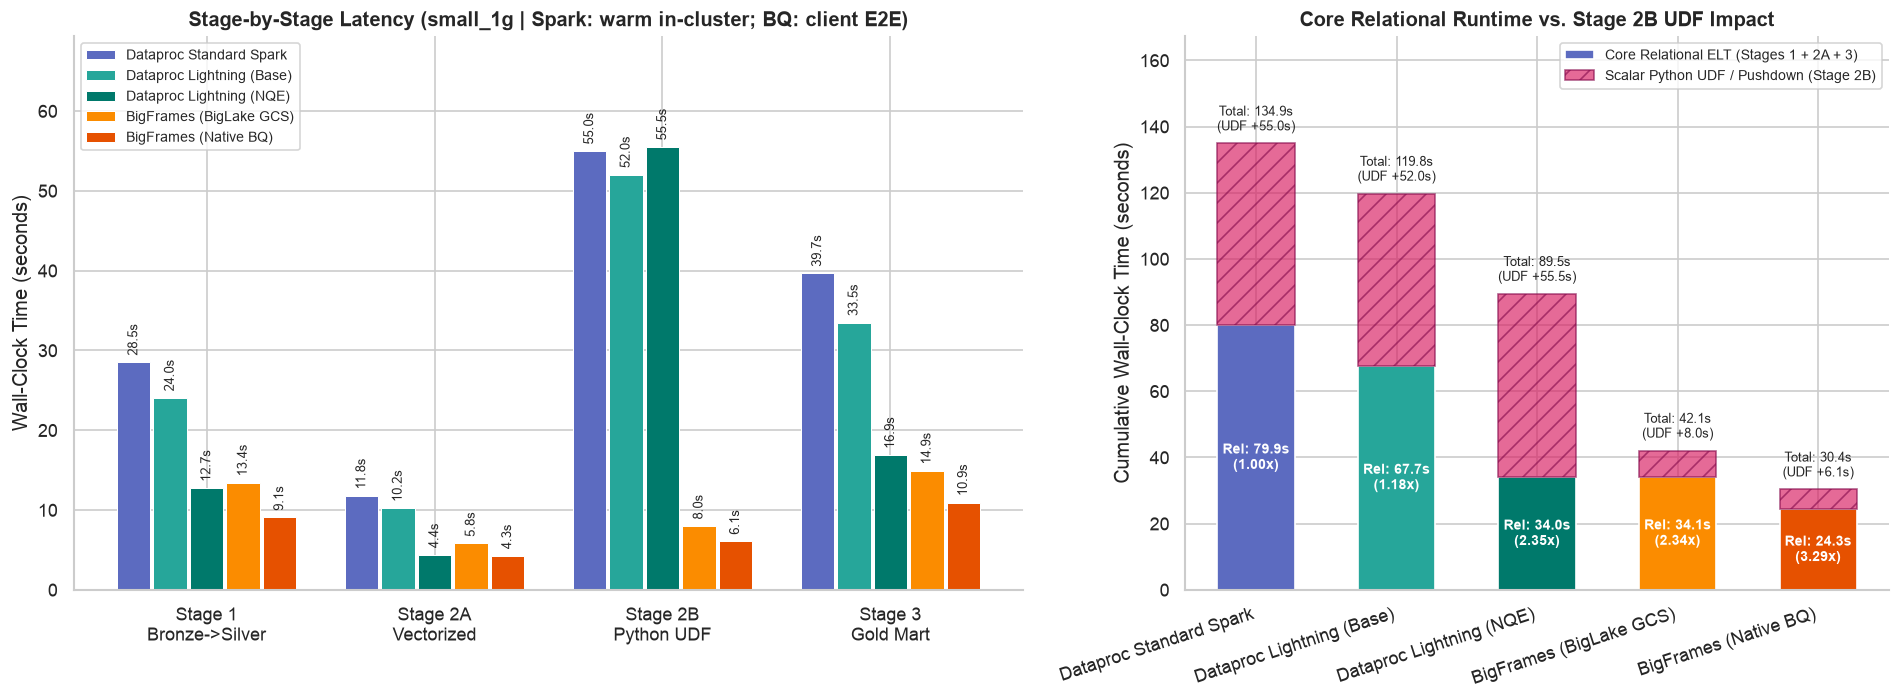

In [4]:
# ==============================================================================
# 4. STAGE LATENCY BREAKDOWN TABLE & GROUPED / STACKED BAR CHARTS
# ==============================================================================
lat_pivot = df.pivot(index="engine_variant", columns="stage_id", values="wall_clock_sec").reindex(
    index=present_engines, columns=present_stages
).fillna(0.0)

core_cols = [s for s in CORE_RELATIONAL_STAGES if s in lat_pivot.columns]
lat_summary = lat_pivot.copy()
lat_summary["relational_total_sec"] = lat_summary[core_cols].sum(axis=1)
lat_summary["udf_stage2b_sec"] = lat_summary["stage2b_silver_udf"] if "stage2b_silver_udf" in lat_summary.columns else 0.0
lat_summary["full_total_sec"] = lat_summary["relational_total_sec"] + lat_summary["udf_stage2b_sec"]

std_rel = lat_summary.loc[ref_engine, "relational_total_sec"]
std_full = lat_summary.loc[ref_engine, "full_total_sec"]
lat_summary["rel_speedup_vs_ref"] = std_rel / lat_summary["relational_total_sec"]
lat_summary["full_speedup_vs_ref"] = std_full / lat_summary["full_total_sec"]

show_table(
    lat_summary.rename(index=ENGINE_LABELS),
    {
        **{s: "{:.2f} s" for s in present_stages},
        "relational_total_sec": "{:.2f} s",
        "udf_stage2b_sec": "{:.2f} s",
        "full_total_sec": "{:.2f} s",
        "rel_speedup_vs_ref": "{:.2f}x",
        "full_speedup_vs_ref": "{:.2f}x",
    },
)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1.35, 1.0]})

# Left panel: Grouped bar chart per stage
x = np.arange(len(present_stages))
bar_w = 0.8 / max(1, len(present_engines))
max_stage_lat = float(lat_pivot.values.max()) if lat_pivot.size else 1.0
for idx, eng in enumerate(present_engines):
    vals = [float(lat_pivot.loc[eng, s]) for s in present_stages]
    offset = (idx - (len(present_engines) - 1) / 2.0) * bar_w
    bars = ax1.bar(
        x + offset,
        vals,
        width=bar_w * 0.92,
        label=ENGINE_LABELS[eng],
        color=ENGINE_PALETTE[eng],
        edgecolor="white",
        linewidth=0.6,
    )
    for bar, v in zip(bars, vals):
        ax1.text(
            bar.get_x() + bar.get_width() / 2.0,
            v + max(max_stage_lat * 0.015, 0.3),
            f"{v:.1f}s",
            ha="center",
            va="bottom",
            fontsize=7.5,
            rotation=90 if len(present_engines) >= 4 else 0,
        )

ax1.set_xticks(x)
ax1.set_xticklabels([STAGE_SHORT_LABELS.get(s, s) for s in present_stages])
ax1.set_ylabel("Wall-Clock Time (seconds)")
ax1.set_title(f"Stage-by-Stage Latency ({ACTIVE_SCALE_PRESET} | Spark: warm in-cluster; BQ: client E2E)")
ax1.set_ylim(0, max_stage_lat * 1.25)
ax1.legend(frameon=True, fontsize=8.5, loc="upper left")

# Right panel: Stacked Core Relational (1+2A+3) vs Python UDF (2B)
y_labels = [ENGINE_LABELS[e] for e in present_engines]
rel_vals = lat_summary["relational_total_sec"].values
udf_vals = lat_summary["udf_stage2b_sec"].values
x2 = np.arange(len(present_engines))

ax2.bar(
    x2,
    rel_vals,
    width=0.55,
    color=[ENGINE_PALETTE[e] for e in present_engines],
    label="Core Relational ELT (Stages 1 + 2A + 3)",
    edgecolor="white",
)
if np.any(udf_vals > 0):
    ax2.bar(
        x2,
        udf_vals,
        width=0.55,
        bottom=rel_vals,
        color="#D81B60",
        alpha=0.65,
        hatch="//",
        edgecolor="#880E4F",
        label="Scalar Python UDF / Pushdown (Stage 2B)",
    )

max_tot = float((rel_vals + udf_vals).max())
for idx, eng in enumerate(present_engines):
    r_v = rel_vals[idx]
    u_v = udf_vals[idx]
    tot_v = r_v + u_v
    sp = lat_summary.loc[eng, "rel_speedup_vs_ref"]
    ax2.text(idx, r_v / 2.0, f"Rel: {r_v:.1f}s\n({sp:.2f}x)", ha="center", va="center", color="white", fontweight="bold", fontsize=8.5)
    if u_v > 0:
        ax2.text(idx, tot_v + max_tot * 0.02, f"Total: {tot_v:.1f}s\n(UDF +{u_v:.1f}s)", ha="center", va="bottom", fontsize=8)

ax2.set_xticks(x2)
ax2.set_xticklabels(y_labels, rotation=18, ha="right")
ax2.set_ylabel("Cumulative Wall-Clock Time (seconds)")
ax2.set_title("Core Relational Runtime vs. Stage 2B UDF Impact")
ax2.set_ylim(0, max_tot * 1.24)
ax2.legend(frameon=True, fontsize=8.5, loc="upper right")

plt.tight_layout()
plt.show()


## 5. Execution Timeline Waterfall (Gantt)

Each engine's `start_epoch_sec -> end_epoch_sec` sequence is normalized to **`t = 0`** at its Stage 1 start so sequential pipeline progress (`Stage 1 -> 2A -> 2B -> 3`) and outside-timer validation gaps align cleanly across engines.


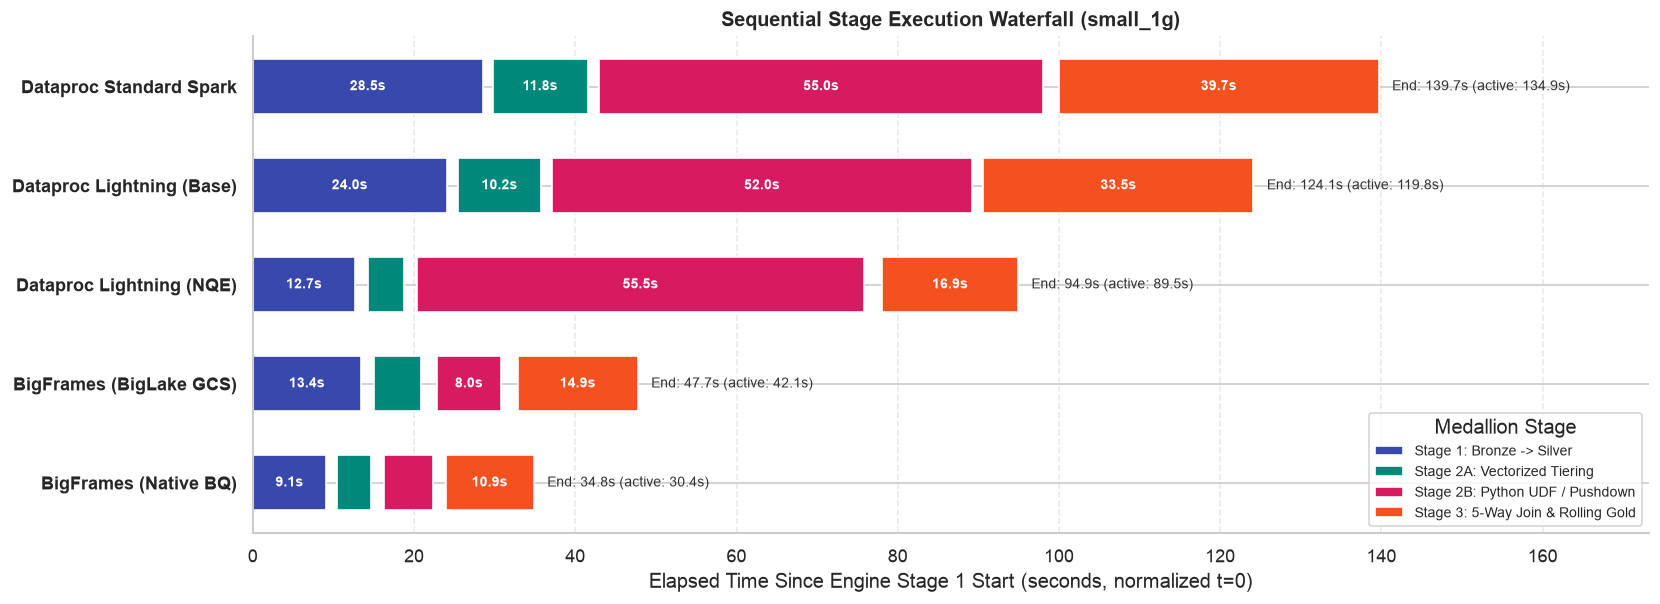

In [5]:
# ==============================================================================
# 5. NORMALIZED EXECUTION TIMELINE GANTT / WATERFALL CHART
# ==============================================================================
gantt_df = df.copy()
t0_by_engine = gantt_df.groupby("engine_variant")["start_epoch_sec"].transform("min")
gantt_df["rel_start_sec"] = gantt_df["start_epoch_sec"] - t0_by_engine
gantt_df["rel_end_sec"] = gantt_df["end_epoch_sec"] - t0_by_engine
gantt_df["duration_sec"] = gantt_df["end_epoch_sec"] - gantt_df["start_epoch_sec"]

inter_gaps = []
for eng in present_engines:
    sub = gantt_df[gantt_df["engine_variant"] == eng].sort_values("start_epoch_sec")
    gaps = sub["start_epoch_sec"].iloc[1:].values - sub["end_epoch_sec"].iloc[:-1].values
    if len(gaps) > 0:
        inter_gaps.append(float(np.max(gaps)))
max_gap = max(inter_gaps) if inter_gaps else 0.0
if max_gap > 60.0:
    print(
        f"Note: Max inter-stage gap of {max_gap:.1f}s detected (typical when running cells interactively). "
        "Showing true normalized epoch offsets; see Section 4 for pure compute time."
    )

fig, ax = plt.subplots(figsize=(14, 5.2))
y_positions = np.arange(len(present_engines))
max_rel_end = float(gantt_df["rel_end_sec"].max())

plotted_stages = set()
for y_idx, eng in enumerate(present_engines):
    sub = gantt_df[gantt_df["engine_variant"] == eng].sort_values("rel_start_sec")
    for _, row in sub.iterrows():
        stg = row["stage_id"]
        label = STAGE_LABELS[stg] if stg not in plotted_stages else None
        plotted_stages.add(stg)
        left = float(row["rel_start_sec"])
        width = float(row["duration_sec"])
        ax.barh(
            y_idx,
            width,
            left=left,
            height=0.56,
            color=STAGE_COLORS[stg],
            edgecolor="white",
            linewidth=1.0,
            label=label,
        )
        if width >= max_rel_end * 0.045:
            ax.text(
                left + width / 2.0,
                y_idx,
                f"{width:.1f}s",
                ha="center",
                va="center",
                color="white",
                fontweight="bold",
                fontsize=8.5,
            )

    total_span = float(sub["rel_end_sec"].max())
    compute_sum = float(sub["wall_clock_sec"].sum())
    ax.text(
        total_span + max_rel_end * 0.012,
        y_idx,
        f"End: {total_span:.1f}s (active: {compute_sum:.1f}s)",
        va="center",
        ha="left",
        fontsize=8.5,
        color="#333333",
    )

ax.set_yticks(y_positions)
ax.set_yticklabels([ENGINE_LABELS[e] for e in present_engines], fontweight="bold")
ax.invert_yaxis()
ax.set_xlabel("Elapsed Time Since Engine Stage 1 Start (seconds, normalized t=0)")
ax.set_title(f"Sequential Stage Execution Waterfall ({ACTIVE_SCALE_PRESET})")
ax.set_xlim(0, max_rel_end * 1.24)
ax.legend(title="Medallion Stage", loc="lower right", frameon=True, fontsize=8.5)
ax.grid(axis="x", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()


## 6. Empirical Compute Equivalency (`Provisioned Spark Worker vCPU-s / Consumed BQ Slot-s`)

This ratio compares **provisioned Spark worker `vcpu_seconds` (`total_worker_vcpus × wall_clock_sec`)** against **actually consumed BigQuery `bq_slot_seconds` (`bq_total_slot_ms / 1000.0`)**:
- **Metric Caveat (`Provisioned` vs. `Consumed`):** Spark `vcpu_seconds` bills/counts *all* allocated worker vCPUs (`16` vCPUs) continuously across each stage even during shuffle waits or single-partition tail tasks, whereas BigQuery `bq_slot_seconds` reflects actual Dremel slot-time consumed (freeing unused capacity in `0s`).
- **Storage Parity Scope Across Stages:**
  - **`Stage 1` (Bronze -> Silver):** **True identical-storage Parquet parity** between Spark (`gs://.../bronze/.../*.parquet`) and `bigframes_biglake_gcs` (`DS_BRONZE_BIGLAKE` over the exact same Parquet files), contrasted against `bigframes_native_bq` (`DS_BRONZE_NATIVE` Capacitor `PHYSICAL`).
  - **`Stages 2A / 2B / 3`:** Spark continues on GCS Parquet intermediates, whereas **both** BigFrames passes materialize and query native BigQuery `DS_SILVER_BQ` intermediates (`Stage 3` also joins against `DS_BRONZE_BIGLAKE` vs `DS_BRONZE_NATIVE` dimensions).



--- Ratio: Provisioned Spark vCPU-s / Consumed BQ Slot-s vs. BigLake Pass (Identical GCS Parquet in Stage 1; Native BQ Silver in 2A/2B/3) ---


,bq_slot_sec,bq_avg_active_slots,bq_mib_processed,spark_standard,spark_lightning_base,spark_lightning_nqe
stage_group,,,,,,
stage1_bronze_to_silver,512.6 slot-s,38.2 slots,408.6 MiB,0.89 vCPU/slot,0.75 vCPU/slot,0.40 vCPU/slot
stage2a_silver_vectorized,148.2 slot-s,25.5 slots,297.9 MiB,1.27 vCPU/slot,1.10 vCPU/slot,0.47 vCPU/slot
stage2b_silver_udf,237.6 slot-s,29.7 slots,297.9 MiB,3.70 vCPU/slot,3.50 vCPU/slot,3.74 vCPU/slot
stage3_silver_to_gold,636.2 slot-s,42.7 slots,463.7 MiB,1.00 vCPU/slot,0.84 vCPU/slot,0.42 vCPU/slot
CORE_RELATIONAL (1+2A+3),"1,297.0 slot-s",38.0 slots,"1,170.3 MiB",0.99 vCPU/slot,0.84 vCPU/slot,0.42 vCPU/slot
ALL_STAGES,"1,534.5 slot-s",36.5 slots,"1,468.2 MiB",1.41 vCPU/slot,1.25 vCPU/slot,0.93 vCPU/slot



--- Ratio: Provisioned Spark vCPU-s / Consumed BQ Slot-s vs. Native BQ Capacitor Pass ---


,bq_slot_sec,bq_avg_active_slots,bq_mib_processed,spark_standard,spark_lightning_base,spark_lightning_nqe
stage_group,,,,,,
stage1_bronze_to_silver,337.7 slot-s,37.2 slots,237.4 MiB,1.35 vCPU/slot,1.14 vCPU/slot,0.60 vCPU/slot
stage2a_silver_vectorized,111.3 slot-s,26.1 slots,187.3 MiB,1.69 vCPU/slot,1.47 vCPU/slot,0.63 vCPU/slot
stage2b_silver_udf,183.3 slot-s,30.1 slots,187.3 MiB,4.80 vCPU/slot,4.54 vCPU/slot,4.85 vCPU/slot
stage3_silver_to_gold,443.7 slot-s,40.6 slots,270.9 MiB,1.43 vCPU/slot,1.21 vCPU/slot,0.61 vCPU/slot
CORE_RELATIONAL (1+2A+3),892.7 slot-s,36.8 slots,695.6 MiB,1.43 vCPU/slot,1.21 vCPU/slot,0.61 vCPU/slot
ALL_STAGES,"1,076.0 slot-s",35.4 slots,882.9 MiB,2.01 vCPU/slot,1.78 vCPU/slot,1.33 vCPU/slot



--- BigFrames BigLake Pass vs. Native Capacitor Pass (By Storage Scope) ---


,storage_comparison_scope,biglake_slot_sec,native_slot_sec,slot_ms_delta_pct,biglake_mib,native_mib,io_bytes_delta_pct
stage1_bronze_to_silver,Bronze Read: BigLake Parquet vs. Capacitor (True Storage Delta),512.6,337.7,+34.1%,408.6,237.4,+41.9%
stage2a_silver_vectorized,Silver Read: Native BQ in Both Passes (Run Variance Only),148.2,111.3,+24.9%,297.9,187.3,+37.1%
stage2b_silver_udf,Silver Read: Native BQ in Both Passes (Run Variance Only),237.6,183.3,+22.8%,297.9,187.3,+37.1%
stage3_silver_to_gold,Mixed: Native BQ Silver + BigLake vs. Native Bronze Dims,636.2,443.7,+30.3%,463.7,270.9,+41.6%


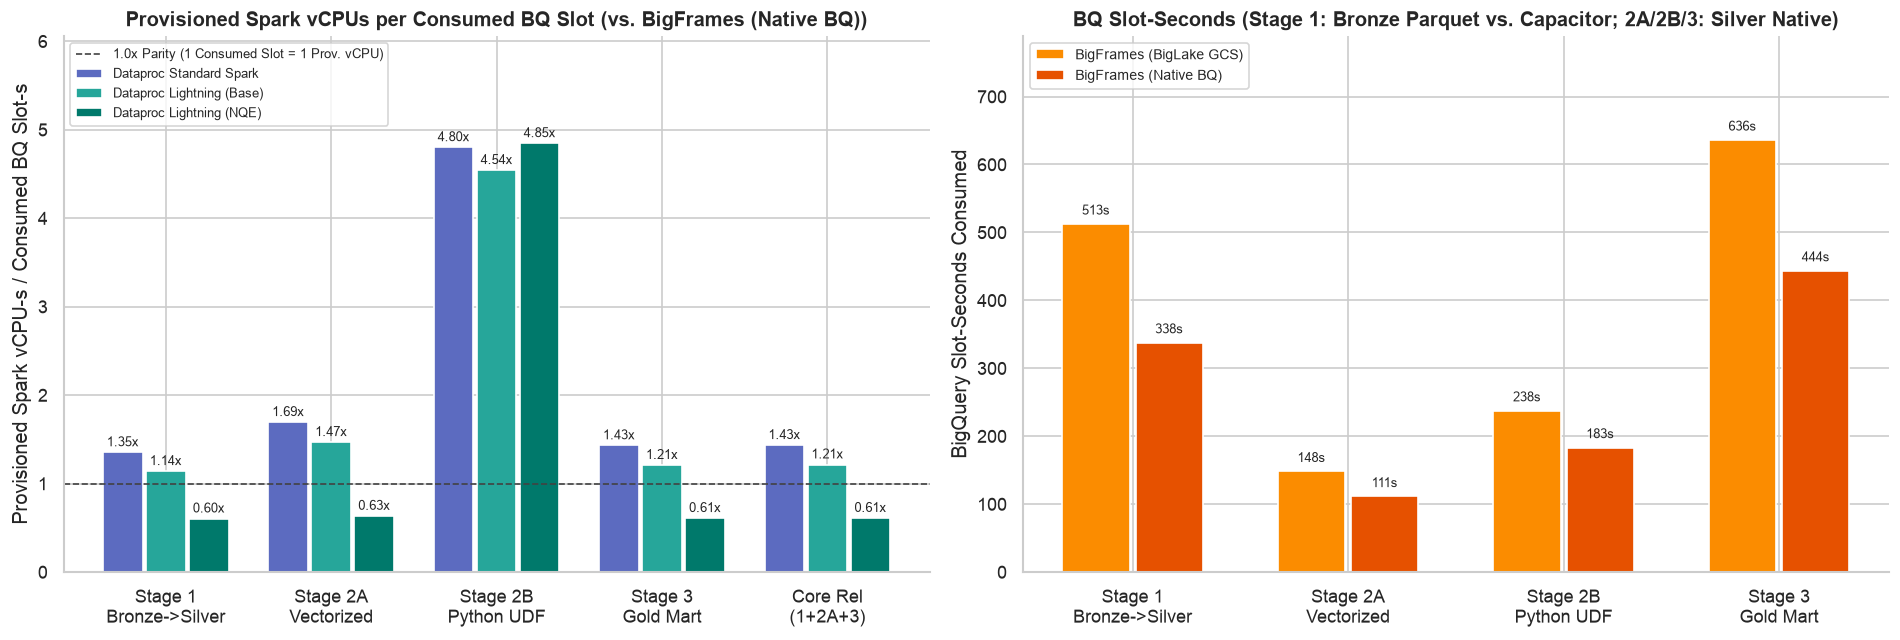

In [6]:
# ==============================================================================
# 6. EMPIRICAL COMPUTE EQUIVALENCY TABLE & STORAGE COMPARISON VISUAL
# ==============================================================================
spark_variants = [e for e in ["spark_standard", "spark_lightning_base", "spark_lightning_nqe"] if e in present_engines]
bq_variants = [e for e in ["bigframes_biglake_gcs", "bigframes_native_bq"] if e in present_engines]

if spark_variants and bq_variants:
    agg_groups = {
        **{s: [s] for s in present_stages},
        "CORE_RELATIONAL (1+2A+3)": [s for s in CORE_RELATIONAL_STAGES if s in present_stages],
        "ALL_STAGES": present_stages,
    }

    eq_records = []
    for group_name, stg_list in agg_groups.items():
        sub = df[df["stage_id"].isin(stg_list)]
        for bq_eng in bq_variants:
            bq_sub = sub[sub["engine_variant"] == bq_eng]
            if bq_sub.empty:
                continue
            bq_slot_s = float(bq_sub["bq_slot_seconds"].sum())
            bq_wall_s = float(bq_sub["wall_clock_sec"].sum())
            bq_avg_slots = bq_slot_s / bq_wall_s if bq_wall_s > 0 else np.nan
            bq_mib = float(bq_sub["bq_mib_processed"].sum())

            for sp_eng in spark_variants:
                sp_sub = sub[sub["engine_variant"] == sp_eng]
                if sp_sub.empty:
                    continue
                sp_vcpu_s = float(sp_sub["vcpu_seconds"].sum())
                spark_vcpus_per_bq_slot = sp_vcpu_s / bq_slot_s if bq_slot_s > 0 else np.nan
                bq_slots_per_spark_vcpu = bq_slot_s / sp_vcpu_s if sp_vcpu_s > 0 else np.nan
                eq_records.append({
                    "stage_group": group_name,
                    "bq_baseline": bq_eng,
                    "spark_variant": sp_eng,
                    "spark_vcpu_sec": sp_vcpu_s,
                    "bq_slot_sec": bq_slot_s,
                    "bq_avg_active_slots": bq_avg_slots,
                    "bq_mib_processed": bq_mib,
                    "spark_vcpus_per_1_bq_slot": spark_vcpus_per_bq_slot,
                    "bq_slots_per_1_spark_vcpu": bq_slots_per_spark_vcpu,
                })

    eq_df = pd.DataFrame(eq_records)

    for bq_eng, title_suffix in [
        (
            "bigframes_biglake_gcs",
            "Provisioned Spark vCPU-s / Consumed BQ Slot-s vs. BigLake Pass (Identical GCS Parquet in Stage 1; Native BQ Silver in 2A/2B/3)",
        ),
        (
            "bigframes_native_bq",
            "Provisioned Spark vCPU-s / Consumed BQ Slot-s vs. Native BQ Capacitor Pass",
        ),
    ]:
        if bq_eng not in bq_variants:
            continue
        sub_eq = eq_df[eq_df["bq_baseline"] == bq_eng]
        piv = sub_eq.pivot(index="stage_group", columns="spark_variant", values="spark_vcpus_per_1_bq_slot").reindex(
            index=list(agg_groups.keys()), columns=spark_variants
        )
        bq_meta = sub_eq.drop_duplicates("stage_group").set_index("stage_group")[
            ["bq_slot_sec", "bq_avg_active_slots", "bq_mib_processed"]
        ]
        table = bq_meta.join(piv)
        print(f"\n--- Ratio: {title_suffix} ---")
        show_table(
            table,
            {
                "bq_slot_sec": "{:,.1f} slot-s",
                "bq_avg_active_slots": "{:.1f} slots",
                "bq_mib_processed": "{:,.1f} MiB",
                **{s: "{:.2f} vCPU/slot" for s in spark_variants},
            },
        )

    # BigLake Pass -> Native Capacitor Pass Delta (highlighting true Bronze vs Silver storage scope)
    if {"bigframes_biglake_gcs", "bigframes_native_bq"}.issubset(set(bq_variants)):
        _scope_labels = {
            "stage1_bronze_to_silver": "Bronze Read: BigLake Parquet vs. Capacitor (True Storage Delta)",
            "stage2a_silver_vectorized": "Silver Read: Native BQ in Both Passes (Run Variance Only)",
            "stage2b_silver_udf": "Silver Read: Native BQ in Both Passes (Run Variance Only)",
            "stage3_silver_to_gold": "Mixed: Native BQ Silver + BigLake vs. Native Bronze Dims",
        }
        cap_df = df[df["engine_variant"].isin(["bigframes_biglake_gcs", "bigframes_native_bq"])].pivot(
            index="stage_id", columns="engine_variant", values=["bq_slot_seconds", "bq_mib_processed", "wall_clock_sec"]
        ).reindex(present_stages)
        cap_summary = pd.DataFrame({
            "storage_comparison_scope": [_scope_labels.get(s, s) for s in present_stages],
            "biglake_slot_sec": cap_df[("bq_slot_seconds", "bigframes_biglake_gcs")],
            "native_slot_sec": cap_df[("bq_slot_seconds", "bigframes_native_bq")],
            "slot_ms_delta_pct": (
                1.0 - cap_df[("bq_slot_seconds", "bigframes_native_bq")] / cap_df[("bq_slot_seconds", "bigframes_biglake_gcs")]
            ) * 100.0,
            "biglake_mib": cap_df[("bq_mib_processed", "bigframes_biglake_gcs")],
            "native_mib": cap_df[("bq_mib_processed", "bigframes_native_bq")],
            "io_bytes_delta_pct": (
                1.0 - cap_df[("bq_mib_processed", "bigframes_native_bq")] / cap_df[("bq_mib_processed", "bigframes_biglake_gcs")]
            ) * 100.0,
        }, index=present_stages)
        print("\n--- BigFrames BigLake Pass vs. Native Capacitor Pass (By Storage Scope) ---")
        show_table(
            cap_summary,
            {
                "biglake_slot_sec": "{:,.1f}",
                "native_slot_sec": "{:,.1f}",
                "slot_ms_delta_pct": "{:+.1f}%",
                "biglake_mib": "{:,.1f}",
                "native_mib": "{:,.1f}",
                "io_bytes_delta_pct": "{:+.1f}%",
            },
        )

    # Visualization
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5.5))

    groups_order = present_stages + ["CORE_RELATIONAL (1+2A+3)"]
    primary_bq = "bigframes_native_bq" if "bigframes_native_bq" in bq_variants else bq_variants[0]
    plot_eq = eq_df[(eq_df["bq_baseline"] == primary_bq) & (eq_df["stage_group"].isin(groups_order))].copy()
    x = np.arange(len(groups_order))
    bw = 0.78 / max(1, len(spark_variants))
    for i, sp_eng in enumerate(spark_variants):
        vals = [
            float(plot_eq.loc[(plot_eq["stage_group"] == g) & (plot_eq["spark_variant"] == sp_eng), "spark_vcpus_per_1_bq_slot"].iloc[0])
            for g in groups_order
        ]
        offset = (i - (len(spark_variants) - 1) / 2.0) * bw
        bars = ax1.bar(x + offset, vals, width=bw * 0.92, label=ENGINE_LABELS[sp_eng], color=ENGINE_PALETTE[sp_eng])
        for bar, v in zip(bars, vals):
            ax1.text(bar.get_x() + bar.get_width() / 2.0, v + 0.04, f"{v:.2f}x", ha="center", va="bottom", fontsize=7.5)

    ax1.axhline(1.0, color="#424242", linestyle="--", linewidth=1.0, label="1.0x Parity (1 Consumed Slot = 1 Prov. vCPU)")
    ax1.set_xticks(x)
    ax1.set_xticklabels([STAGE_SHORT_LABELS.get(g, g) for g in groups_order])
    ax1.set_ylabel("Provisioned Spark vCPU-s / Consumed BQ Slot-s")
    ax1.set_title(f"Provisioned Spark vCPUs per Consumed BQ Slot (vs. {ENGINE_LABELS[primary_bq]})")
    ax1.set_ylim(0, max(1.25, float(plot_eq["spark_vcpus_per_1_bq_slot"].max()) * 1.25))
    ax1.legend(fontsize=8, loc="upper left")

    # Right panel: BigLake Pass vs Native BQ Pass slot-seconds
    bq_plot_df = df[df["engine_variant"].isin(bq_variants)].copy()
    x_s = np.arange(len(present_stages))
    bw2 = 0.68 / max(1, len(bq_variants))
    max_slot_s = float(bq_plot_df["bq_slot_seconds"].max())
    for idx, bq_eng in enumerate(bq_variants):
        vals = [
            float(bq_plot_df.loc[(bq_plot_df["engine_variant"] == bq_eng) & (bq_plot_df["stage_id"] == s), "bq_slot_seconds"].iloc[0])
            for s in present_stages
        ]
        offset2 = (idx - (len(bq_variants) - 1) / 2.0) * bw2
        bars = ax2.bar(
            x_s + offset2,
            vals,
            width=bw2 * 0.92,
            label=ENGINE_LABELS[bq_eng],
            color=ENGINE_PALETTE[bq_eng],
        )
        for bar, v in zip(bars, vals):
            ax2.text(bar.get_x() + bar.get_width() / 2.0, v + max_slot_s * 0.015, f"{v:.0f}s", ha="center", va="bottom", fontsize=8)
    ax2.set_xticks(x_s)
    ax2.set_xticklabels([STAGE_SHORT_LABELS.get(s, s) for s in present_stages])
    ax2.set_ylabel("BigQuery Slot-Seconds Consumed")
    ax2.set_title("BQ Slot-Seconds (Stage 1: Bronze Parquet vs. Capacitor; 2A/2B/3: Silver Native)")
    ax2.set_ylim(0, max_slot_s * 1.24)
    ax2.legend(fontsize=8.5, loc="upper left")

    plt.tight_layout()
    plt.show()
else:
    eq_df = pd.DataFrame()
    print("Compute equivalency requires at least one Spark and one BigFrames variant.")


## 7. Stage 2A Vectorized vs. Stage 2B Python UDF Fallback Analysis

On `medium_100g` and `large_500g`, Stage 2B operates on a deterministic `5%` slice (`sample_fraction ≈ 0.05`) to measure Python UDF overhead safely. Normalizing latency by `sample_fraction` (`effective_full_sec = wall_clock_sec / sample_fraction`) exposes the true per-row slowdown:
- **Dataproc Lightning + NQE (`runtime=native`):** Columnar Velox C++ execution cannot execute arbitrary Python `@F.udf` bytecode natively, forcing `VeloxColumnarToRow -> BatchEvalPythonExec -> RowToVeloxColumnar` JVM/Python pickle fallback.
- **BigFrames (`ordering_mode="partial"`):** Modular Python scoring functions built over `BigFrames` Series expressions compile directly to distributed GoogleSQL pushdown inside the slot reservation (`$0` extra UDF container cost). Arbitrary third-party Python libraries requiring `@bpd.udf` (Managed Python UDF) bill separately under `BigQuery Services` SKU outside slot reservations.


,2a_wall_sec,2b_wall_sec,2b_sample_fraction,2b_full_scale_equiv_sec,2a_sec_per_1m_rows,2b_sec_per_1m_rows,udf_slowdown_factor,nqe_fallback_note
engine_variant,,,,,,,,
Dataproc Standard Spark,11.77 s,54.99 s,100.00%,54.99 s,3.42 s/M,16.00 s/M,4.67x,
Dataproc Lightning (Base),10.20 s,52.03 s,100.00%,52.03 s,2.97 s/M,15.14 s/M,5.10x,
Dataproc Lightning (NQE),4.40 s,55.51 s,100.00%,55.51 s,1.28 s/M,16.15 s/M,12.62x,VeloxColumnarToRow -> BatchEvalPythonExec -> RowToVeloxColumnar (scalar PySpark @F.udf falls back to JVM/Python workers)
BigFrames (BigLake GCS),5.81 s,7.99 s,100.00%,7.99 s,1.69 s/M,2.32 s/M,1.38x,
BigFrames (Native BQ),4.27 s,6.08 s,100.00%,6.08 s,1.24 s/M,1.77 s/M,1.42x,



Captured NQE Physical Plan Fallback Telemetry:
  [spark_lightning_nqe] VeloxColumnarToRow -> BatchEvalPythonExec -> RowToVeloxColumnar (scalar PySpark @F.udf falls back to JVM/Python workers)


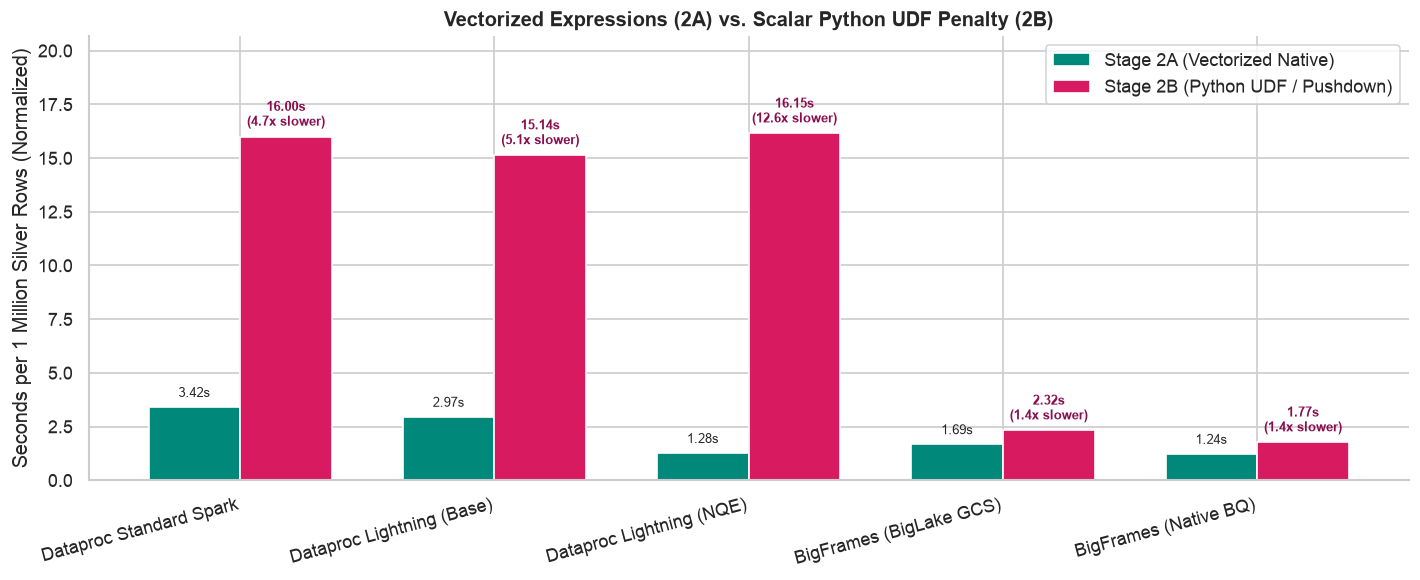

In [7]:
# ==============================================================================
# 7. STAGE 2A VECTORIZED VS. STAGE 2B PYTHON UDF NORMALIZED ANALYSIS
# ==============================================================================
if {"stage2a_silver_vectorized", "stage2b_silver_udf"}.issubset(set(present_stages)):
    s2_rows = []
    for eng in present_engines:
        sub2a = df[(df["engine_variant"] == eng) & (df["stage_id"] == "stage2a_silver_vectorized")]
        sub2b = df[(df["engine_variant"] == eng) & (df["stage_id"] == "stage2b_silver_udf")]
        if sub2a.empty or sub2b.empty:
            continue
        r2a = sub2a.iloc[0]
        r2b = sub2b.iloc[0]

        sf_2a = float(r2a["sample_fraction"])
        sf_2b = float(r2b["sample_fraction"])
        norm_2a_sec = float(r2a["wall_clock_sec"]) / sf_2a
        norm_2b_sec = float(r2b["wall_clock_sec"]) / sf_2b
        slowdown_factor = norm_2b_sec / norm_2a_sec

        sec_per_1m_2a = float(r2a["wall_clock_sec"]) / (float(r2a["output_row_count"]) / 1e6)
        sec_per_1m_2b = float(r2b["wall_clock_sec"]) / (float(r2b["output_row_count"]) / 1e6)

        s2_rows.append({
            "engine_variant": eng,
            "2a_wall_sec": float(r2a["wall_clock_sec"]),
            "2b_wall_sec": float(r2b["wall_clock_sec"]),
            "2b_sample_fraction": sf_2b,
            "2b_full_scale_equiv_sec": norm_2b_sec,
            "2a_sec_per_1m_rows": sec_per_1m_2a,
            "2b_sec_per_1m_rows": sec_per_1m_2b,
            "udf_slowdown_factor": slowdown_factor,
            "nqe_fallback_note": str(r2b.get("nqe_fallback_note", "") or ""),
        })

    udf_df = pd.DataFrame(s2_rows)
    show_table(
        udf_df.set_index("engine_variant").rename(index=ENGINE_LABELS),
        {
            "2a_wall_sec": "{:.2f} s",
            "2b_wall_sec": "{:.2f} s",
            "2b_sample_fraction": "{:.2%}",
            "2b_full_scale_equiv_sec": "{:.2f} s",
            "2a_sec_per_1m_rows": "{:.2f} s/M",
            "2b_sec_per_1m_rows": "{:.2f} s/M",
            "udf_slowdown_factor": "{:.2f}x",
        },
    )

    notes = udf_df[udf_df["nqe_fallback_note"].str.len() > 0]
    if not notes.empty:
        print("\nCaptured NQE Physical Plan Fallback Telemetry:")
        for _, nrow in notes.iterrows():
            print(f"  [{nrow['engine_variant']}] {nrow['nqe_fallback_note']}")

    fig, ax = plt.subplots(figsize=(12, 5))
    x = np.arange(len(udf_df))
    bw = 0.36
    ax.bar(x - bw / 2, udf_df["2a_sec_per_1m_rows"], width=bw, color="#00897B", label="Stage 2A (Vectorized Native)")
    ax.bar(x + bw / 2, udf_df["2b_sec_per_1m_rows"], width=bw, color="#D81B60", label="Stage 2B (Python UDF / Pushdown)")

    max_y = max(udf_df["2a_sec_per_1m_rows"].max(), udf_df["2b_sec_per_1m_rows"].max())
    for idx, row in udf_df.iterrows():
        ax.text(idx - bw / 2, row["2a_sec_per_1m_rows"] + max_y * 0.02, f"{row['2a_sec_per_1m_rows']:.2f}s", ha="center", va="bottom", fontsize=8)
        ratio_lbl = f"{row['udf_slowdown_factor']:.1f}x slower" if row["udf_slowdown_factor"] >= 1.0 else f"{1.0/row['udf_slowdown_factor']:.1f}x faster"
        ax.text(
            idx + bw / 2,
            row["2b_sec_per_1m_rows"] + max_y * 0.02,
            f"{row['2b_sec_per_1m_rows']:.2f}s\n({ratio_lbl})",
            ha="center",
            va="bottom",
            fontsize=8,
            fontweight="bold",
            color="#880E4F",
        )

    ax.set_xticks(x)
    ax.set_xticklabels([ENGINE_LABELS[e] for e in udf_df["engine_variant"]], rotation=15, ha="right")
    ax.set_ylabel("Seconds per 1 Million Silver Rows (Normalized)")
    ax.set_title("Vectorized Expressions (2A) vs. Scalar Python UDF Penalty (2B)")
    ax.set_ylim(0, max_y * 1.28)
    ax.legend(frameon=True, loc="upper right")
    plt.tight_layout()
    plt.show()
else:
    udf_df = pd.DataFrame()
    print("Stage 2B telemetry not present in this run (RUN_PYTHON_UDF_STAGE=false).")


## 8. Lightning Engine Surcharge Break-Even & Parameterized TCO Matrix

We evaluate **Dataproc Standard vs. Dataproc Lightning Engine (`+$0.0025 / vCPU-hr`)** across all 4 cluster purchase blends (`100% On-Demand`, `15% Primary 1-Yr CUD + 85% Spot EFM`, `1-Yr CUD`, `3-Yr CUD`) alongside **BigQuery Enterprise Edition** (`PayGo $0.06`, `1-Yr $0.048`, `3-Yr $0.036 / slot-hr`):

> **TCO Modeling Assumptions & Caveats (`SPEC.md` §4):**
> - **Dataproc Active Stage Cost vs. Cluster Lifetime:** Pricing strictly `active_stage_wall_sec * cluster_hr_rate` assumes a warm, 100%-busy shared cluster. To capture real operational overhead, Section 8B also shows a **Cluster-Lifetime Sensitivity Lens** (`70%` effective cluster utilization or `+120s` ephemeral spin-up/teardown amortization).
> - **Modeled Spot / EFM Blend Caveat:** The `15% Primary (1-Yr CUD) + 85% Spot Secondary (EFM)` column re-prices the measured `2 × n2d-standard-8` hardware shape using modeled Spot discounts (`~65%` off GCE); production EFM clusters with Spot secondary workers can incur minor shuffle/preemption variance not exercised on static 2-worker runs.
> - **Dual BigQuery Billing Lenses:**
>   - **(a) Shared Slot-Hour Consumption:** `bq_slot_seconds / 3600 × slot_rate` (`0s` idle waste when unused capacity immediately serves concurrent workloads in a shared Enterprise reservation).
>   - **(b) Standalone Reservation Ceiling:** `bq_slot_cap × pass_wall_clock_hours × slot_rate` (plus **Lens `b*`** applying BigQuery's `60s` autoscale minimum billable window **across the contiguous pipeline pass** `max(60.0, sum_pass_wall_clock_sec)` rather than `4 × 60s`, and showing `50`-slot autoscale step quantization!).


Lightning Surcharge Break-Even Analysis — Scope: Full Cluster (Master + Workers) (20 vCPUs)


,std_cluster_usd_hr,lgt_cluster_usd_hr,surcharge_usd_hr,req_breakeven_speedup_pct,req_runtime_reduction_pct,measured_base_speedup_pct,base_net_cost_delta_pct,measured_nqe_speedup_pct,nqe_net_cost_delta_pct,nqe_verdict
cluster_blend,,,,,,,,,,
100% On-Demand,$1.2336/hr,$1.2836/hr,+$0.0500/hr,+4.05%,-3.90%,+18.0%,-11.9%,+135.4%,-55.8%,NET SAVINGS
15% Primary (1-Yr CUD) + 85% Spot Secondary (EFM),$0.6722/hr,$0.7222/hr,+$0.0500/hr,+7.44%,-6.92%,+18.0%,-9.0%,+135.4%,-54.4%,NET SAVINGS
100% 1-Yr CUD,$0.8512/hr,$0.9012/hr,+$0.0500/hr,+5.87%,-5.55%,+18.0%,-10.3%,+135.4%,-55.0%,NET SAVINGS
100% 3-Yr CUD,$0.6652/hr,$0.7152/hr,+$0.0500/hr,+7.52%,-6.99%,+18.0%,-8.9%,+135.4%,-54.3%,NET SAVINGS


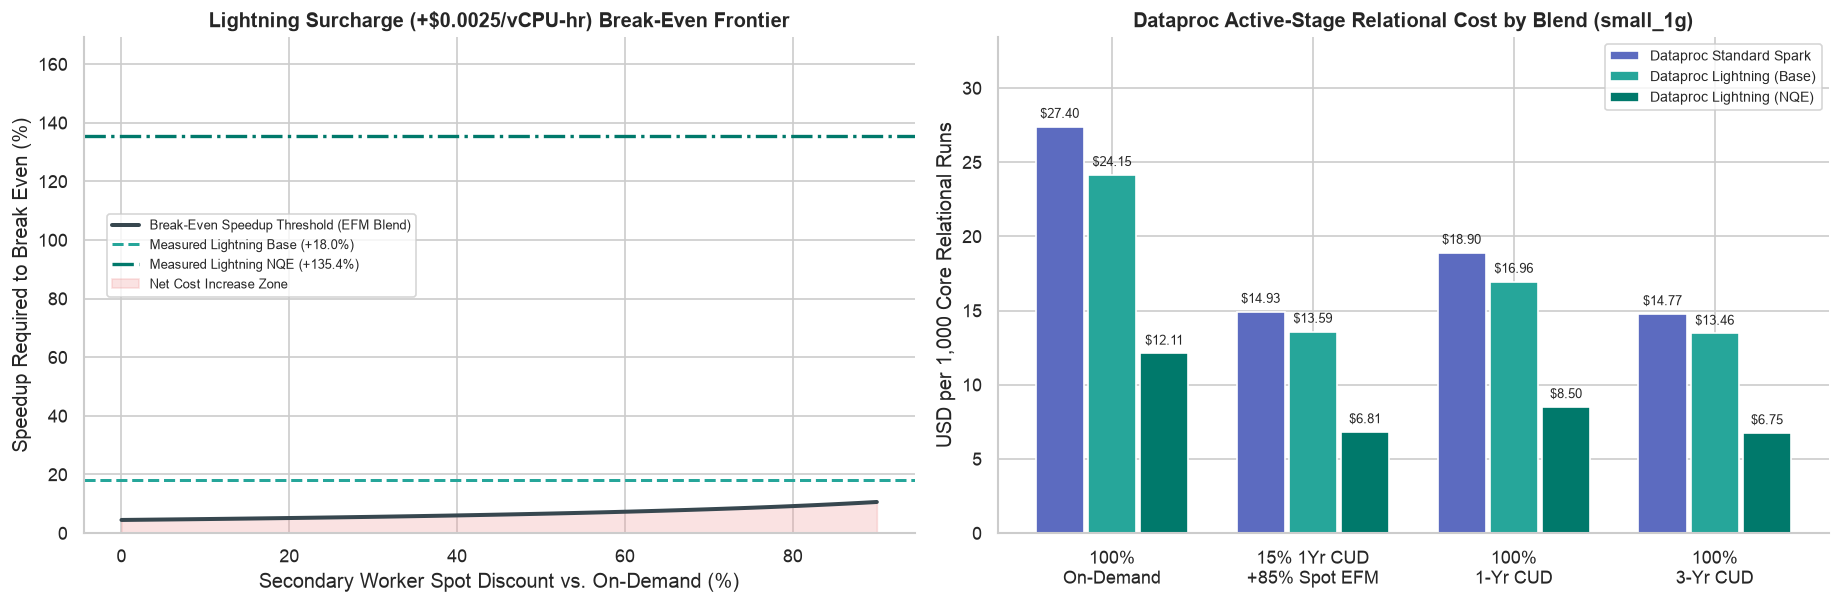

In [8]:
# ==============================================================================
# 8A. DATAPROC BLEND RATE MODEL & LIGHTNING SURCHARGE BREAK-EVEN ANALYSIS
# ==============================================================================
BLEND_WEIGHTS = {
    "100% On-Demand": {"primary_tier": "on_demand", "secondary_tier": "on_demand", "primary_share": 1.0},
    "15% Primary (1-Yr CUD) + 85% Spot Secondary (EFM)": {"primary_tier": "cud_1yr", "secondary_tier": "spot", "primary_share": 0.15},
    "100% 1-Yr CUD": {"primary_tier": "cud_1yr", "secondary_tier": "cud_1yr", "primary_share": 1.0},
    "100% 3-Yr CUD": {"primary_tier": "cud_3yr", "secondary_tier": "cud_3yr", "primary_share": 1.0},
}


def compute_dataproc_hourly_cost(
    blend_name: str,
    topology: dict,
    cfg: dict,
    lightning: bool = False,
    include_master: bool = True,
) -> dict[str, float]:
    """Compute exact hourly USD cluster cost breakdown for a Dataproc GCE pricing blend."""
    spec = BLEND_WEIGHTS[blend_name]
    p_tier = spec["primary_tier"]
    s_tier = spec["secondary_tier"]
    p_share = spec["primary_share"]
    s_share = 1.0 - p_share

    gce = cfg["gce_n2d_standard"]
    ssd_rates = cfg["local_ssd_375gb_hr"]

    m_vcpus = topology["master_vcpus"] if include_master else 0
    m_ram = topology["master_ram_gb"] if include_master else 0
    master_vm_hr = (m_vcpus * gce[p_tier]["vcpu_hr"]) + (m_ram * gce[p_tier]["ram_gb_hr"])

    w_vcpus = topology["worker_vcpus"]
    w_ram = topology["worker_ram_gb"]
    w_ssds = topology["worker_local_ssds"]

    worker_vm_hr = (
        p_share * (w_vcpus * gce[p_tier]["vcpu_hr"] + w_ram * gce[p_tier]["ram_gb_hr"])
        + s_share * (w_vcpus * gce[s_tier]["vcpu_hr"] + w_ram * gce[s_tier]["ram_gb_hr"])
    )
    ssd_hr = w_ssds * (p_share * ssd_rates[p_tier] + s_share * ssd_rates[s_tier])

    total_vcpus = m_vcpus + w_vcpus
    dataproc_fee_hr = total_vcpus * cfg["dataproc_mgmt_fee_per_vcpu_hr"]
    lightning_hr = (total_vcpus * cfg["lightning_surcharge_per_vcpu_hr"]) if lightning else 0.0
    total_hr = master_vm_hr + worker_vm_hr + ssd_hr + dataproc_fee_hr + lightning_hr

    return {
        "total_vcpus_billed": float(total_vcpus),
        "vm_compute_hr": master_vm_hr + worker_vm_hr,
        "local_ssd_hr": ssd_hr,
        "dataproc_fee_hr": dataproc_fee_hr,
        "lightning_surcharge_hr": lightning_hr,
        "total_cluster_hr": total_hr,
        "effective_per_vcpu_hr": total_hr / max(1, total_vcpus),
    }


breakeven_rows = []
std_rel_sec = float(df.loc[(df["engine_variant"] == "spark_standard") & (df["stage_id"].isin(CORE_RELATIONAL_STAGES)), "wall_clock_sec"].sum()) if "spark_standard" in present_engines else np.nan
lgt_base_rel_sec = float(df.loc[(df["engine_variant"] == "spark_lightning_base") & (df["stage_id"].isin(CORE_RELATIONAL_STAGES)), "wall_clock_sec"].sum()) if "spark_lightning_base" in present_engines else np.nan
lgt_nqe_rel_sec = float(df.loc[(df["engine_variant"] == "spark_lightning_nqe") & (df["stage_id"].isin(CORE_RELATIONAL_STAGES)), "wall_clock_sec"].sum()) if "spark_lightning_nqe" in present_engines else np.nan

for blend_name in BLEND_WEIGHTS:
    r_std = compute_dataproc_hourly_cost(blend_name, CLUSTER_TOPOLOGY, PRICING_CONFIG, lightning=False, include_master=INCLUDE_MASTER_IN_TCO)
    r_lgt = compute_dataproc_hourly_cost(blend_name, CLUSTER_TOPOLOGY, PRICING_CONFIG, lightning=True, include_master=INCLUDE_MASTER_IN_TCO)
    req_speedup_pct = ((r_lgt["total_cluster_hr"] / r_std["total_cluster_hr"]) - 1.0) * 100.0
    req_runtime_red_pct = (1.0 - (r_std["total_cluster_hr"] / r_lgt["total_cluster_hr"])) * 100.0

    nqe_speedup_pct = ((std_rel_sec / lgt_nqe_rel_sec) - 1.0) * 100.0 if np.isfinite(std_rel_sec) and np.isfinite(lgt_nqe_rel_sec) else np.nan
    base_speedup_pct = ((std_rel_sec / lgt_base_rel_sec) - 1.0) * 100.0 if np.isfinite(std_rel_sec) and np.isfinite(lgt_base_rel_sec) else np.nan

    nqe_cost_delta_pct = (((r_lgt["total_cluster_hr"] * lgt_nqe_rel_sec) / (r_std["total_cluster_hr"] * std_rel_sec)) - 1.0) * 100.0 if np.isfinite(nqe_speedup_pct) else np.nan
    base_cost_delta_pct = (((r_lgt["total_cluster_hr"] * lgt_base_rel_sec) / (r_std["total_cluster_hr"] * std_rel_sec)) - 1.0) * 100.0 if np.isfinite(base_speedup_pct) else np.nan

    if np.isfinite(nqe_cost_delta_pct):
        nqe_verdict = "NET SAVINGS" if nqe_cost_delta_pct < 0 else "SURCHARGE EXCEEDS SPEEDUP"
    else:
        nqe_verdict = "N/A"

    breakeven_rows.append({
        "cluster_blend": blend_name,
        "std_cluster_usd_hr": r_std["total_cluster_hr"],
        "lgt_cluster_usd_hr": r_lgt["total_cluster_hr"],
        "surcharge_usd_hr": r_lgt["lightning_surcharge_hr"],
        "req_breakeven_speedup_pct": req_speedup_pct,
        "req_runtime_reduction_pct": req_runtime_red_pct,
        "measured_base_speedup_pct": base_speedup_pct,
        "base_net_cost_delta_pct": base_cost_delta_pct,
        "measured_nqe_speedup_pct": nqe_speedup_pct,
        "nqe_net_cost_delta_pct": nqe_cost_delta_pct,
        "nqe_verdict": nqe_verdict,
    })

breakeven_df = pd.DataFrame(breakeven_rows)
scope_note = "Full Cluster (Master + Workers)" if INCLUDE_MASTER_IN_TCO else "Workers Only"
billed_vcpu_cnt = int(CLUSTER_TOPOLOGY["master_vcpus"] + CLUSTER_TOPOLOGY["worker_vcpus"] if INCLUDE_MASTER_IN_TCO else CLUSTER_TOPOLOGY["worker_vcpus"])
print(f"Lightning Surcharge Break-Even Analysis — Scope: {scope_note} ({billed_vcpu_cnt} vCPUs)")
show_table(
    breakeven_df.set_index("cluster_blend"),
    {
        "std_cluster_usd_hr": "${:.4f}/hr",
        "lgt_cluster_usd_hr": "${:.4f}/hr",
        "surcharge_usd_hr": "+${:.4f}/hr",
        "req_breakeven_speedup_pct": "+{:.2f}%",
        "req_runtime_reduction_pct": "-{:.2f}%",
        "measured_base_speedup_pct": "{:+.1f}%",
        "base_net_cost_delta_pct": "{:+.1f}%",
        "measured_nqe_speedup_pct": "{:+.1f}%",
        "nqe_net_cost_delta_pct": "{:+.1f}%",
    },
)

# Break-even sensitivity chart (Spot discount 0% -> 90% vs measured speedups)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15.5, 5.2))

spot_discounts = np.linspace(0.0, 0.90, 50)
req_speedup_curve = []
for disc in spot_discounts:
    gce_od = PRICING_CONFIG["gce_n2d_standard"]["on_demand"]
    gce_1yr = PRICING_CONFIG["gce_n2d_standard"]["cud_1yr"]
    m_v = CLUSTER_TOPOLOGY["master_vcpus"] if INCLUDE_MASTER_IN_TCO else 0
    m_r = CLUSTER_TOPOLOGY["master_ram_gb"] if INCLUDE_MASTER_IN_TCO else 0
    w_v = CLUSTER_TOPOLOGY["worker_vcpus"]
    w_r = CLUSTER_TOPOLOGY["worker_ram_gb"]
    w_s = CLUSTER_TOPOLOGY["worker_local_ssds"]
    std_hr = (
        (m_v * gce_1yr["vcpu_hr"] + m_r * gce_1yr["ram_gb_hr"])
        + 0.15 * (w_v * gce_1yr["vcpu_hr"] + w_r * gce_1yr["ram_gb_hr"] + w_s * PRICING_CONFIG["local_ssd_375gb_hr"]["cud_1yr"])
        + 0.85 * ((1.0 - disc) * (w_v * gce_od["vcpu_hr"] + w_r * gce_od["ram_gb_hr"] + w_s * PRICING_CONFIG["local_ssd_375gb_hr"]["on_demand"]))
        + (m_v + w_v) * PRICING_CONFIG["dataproc_mgmt_fee_per_vcpu_hr"]
    )
    lgt_hr = std_hr + (m_v + w_v) * PRICING_CONFIG["lightning_surcharge_per_vcpu_hr"]
    req_speedup_curve.append(((lgt_hr / std_hr) - 1.0) * 100.0)

ax1.plot(spot_discounts * 100.0, req_speedup_curve, color="#37474F", linewidth=2.4, label="Break-Even Speedup Threshold (EFM Blend)")
max_y_be = max(req_speedup_curve)
if np.isfinite(breakeven_df["measured_base_speedup_pct"].iloc[0]):
    base_sp = float(breakeven_df["measured_base_speedup_pct"].iloc[0])
    max_y_be = max(max_y_be, base_sp)
    ax1.axhline(base_sp, color="#26A69A", linestyle="--", linewidth=1.8, label=f"Measured Lightning Base ({base_sp:+.1f}%)")
if np.isfinite(breakeven_df["measured_nqe_speedup_pct"].iloc[0]):
    nqe_sp = float(breakeven_df["measured_nqe_speedup_pct"].iloc[0])
    max_y_be = max(max_y_be, nqe_sp)
    ax1.axhline(nqe_sp, color="#00796B", linestyle="-.", linewidth=2.0, label=f"Measured Lightning NQE ({nqe_sp:+.1f}%)")
ax1.fill_between(spot_discounts * 100.0, 0, req_speedup_curve, color="#EF9A9A", alpha=0.28, label="Net Cost Increase Zone")
ax1.set_xlabel("Secondary Worker Spot Discount vs. On-Demand (%)")
ax1.set_ylabel("Speedup Required to Break Even (%)")
ax1.set_title("Lightning Surcharge (+$0.0025/vCPU-hr) Break-Even Frontier")
ax1.set_ylim(0, max(20.0, max_y_be * 1.25))
ax1.legend(fontsize=8, loc="center left", bbox_to_anchor=(0.02, 0.56), frameon=True)

# Right panel: Core Relational Cost per 1,000 Runs across the 4 Dataproc Blends
spark_order_present = [e for e in ["spark_standard", "spark_lightning_base", "spark_lightning_nqe"] if e in present_engines]
x_b = np.arange(len(BLEND_WEIGHTS))
bw = 0.78 / max(1, len(spark_order_present))
max_blend_cost = 0.0
all_bar_series = []
for i, eng in enumerate(spark_order_present):
    is_lgt = eng != "spark_standard"
    sec = float(df.loc[(df["engine_variant"] == eng) & (df["stage_id"].isin(CORE_RELATIONAL_STAGES)), "wall_clock_sec"].sum())
    costs_1k = [
        compute_dataproc_hourly_cost(b, CLUSTER_TOPOLOGY, PRICING_CONFIG, lightning=is_lgt, include_master=INCLUDE_MASTER_IN_TCO)["total_cluster_hr"]
        * (sec / 3600.0)
        * 1000.0
        for b in BLEND_WEIGHTS
    ]
    max_blend_cost = max(max_blend_cost, max(costs_1k))
    all_bar_series.append((i, eng, costs_1k))

for i, eng, costs_1k in all_bar_series:
    offset = (i - (len(spark_order_present) - 1) / 2.0) * bw
    bars = ax2.bar(x_b + offset, costs_1k, width=bw * 0.92, label=ENGINE_LABELS[eng], color=ENGINE_PALETTE[eng])
    for bar, v in zip(bars, costs_1k):
        ax2.text(bar.get_x() + bar.get_width() / 2.0, v + max_blend_cost * 0.015, f"${v:.2f}", ha="center", va="bottom", fontsize=7.5)

ax2.set_xticks(x_b)
ax2.set_xticklabels(["100%\nOn-Demand", "15% 1Yr CUD\n+85% Spot EFM", "100%\n1-Yr CUD", "100%\n3-Yr CUD"])
ax2.set_ylabel("USD per 1,000 Core Relational Runs")
ax2.set_title(f"Dataproc Active-Stage Relational Cost by Blend ({ACTIVE_SCALE_PRESET})")
ax2.set_ylim(0, max(1.0, max_blend_cost) * 1.22)
ax2.legend(fontsize=8.5, loc="upper right")

plt.tight_layout()
plt.show()


--- Full Parameterized TCO Matrix (Per Run & Projected 1,000 Runs/Month) ---


,engine_label,pricing_tier,billing_lens,hourly_rate_usd,rel_cost_per_run_usd,full_cost_per_run_usd,rel_cost_1k_runs_usd,full_cost_1k_runs_usd
0,Dataproc Standard Spark,100% On-Demand,Active Stage Time (100% Busy Shared Cluster),$1.2336/hr,$0.02740,$0.04624,$27.40,$46.24
1,Dataproc Standard Spark,100% On-Demand,Cluster-Lifetime (70% Util / Driver Gap),$1.2336/hr,$0.03914,$0.06606,$39.14,$66.06
2,Dataproc Standard Spark,100% On-Demand,Ephemeral Cluster (+120s Spin-Up/Down),$1.2336/hr,$0.06852,$0.08736,$68.52,$87.36
3,Dataproc Standard Spark,15% Primary (1-Yr CUD) + 85% Spot Secondary (EFM),Active Stage Time (100% Busy Shared Cluster),$0.6722/hr,$0.01493,$0.02519,$14.93,$25.19
4,Dataproc Standard Spark,15% Primary (1-Yr CUD) + 85% Spot Secondary (EFM),Cluster-Lifetime (70% Util / Driver Gap),$0.6722/hr,$0.02133,$0.03599,$21.33,$35.99
5,Dataproc Standard Spark,15% Primary (1-Yr CUD) + 85% Spot Secondary (EFM),Ephemeral Cluster (+120s Spin-Up/Down),$0.6722/hr,$0.03733,$0.04760,$37.33,$47.60
6,Dataproc Standard Spark,100% 1-Yr CUD,Active Stage Time (100% Busy Shared Cluster),$0.8512/hr,$0.01890,$0.03191,$18.90,$31.91
7,Dataproc Standard Spark,100% 3-Yr CUD,Active Stage Time (100% Busy Shared Cluster),$0.6652/hr,$0.01477,$0.02493,$14.77,$24.93
8,Dataproc Standard Spark,Worker-Only List Parity (16 vCPUs),Matches telemetry est_list_cost_usd,$1.0033/hr,$0.02228,$0.03761,$22.28,$37.61
9,Dataproc Lightning (Base),100% On-Demand,Active Stage Time (100% Busy Shared Cluster),$1.2836/hr,$0.02415,$0.04270,$24.15,$42.70


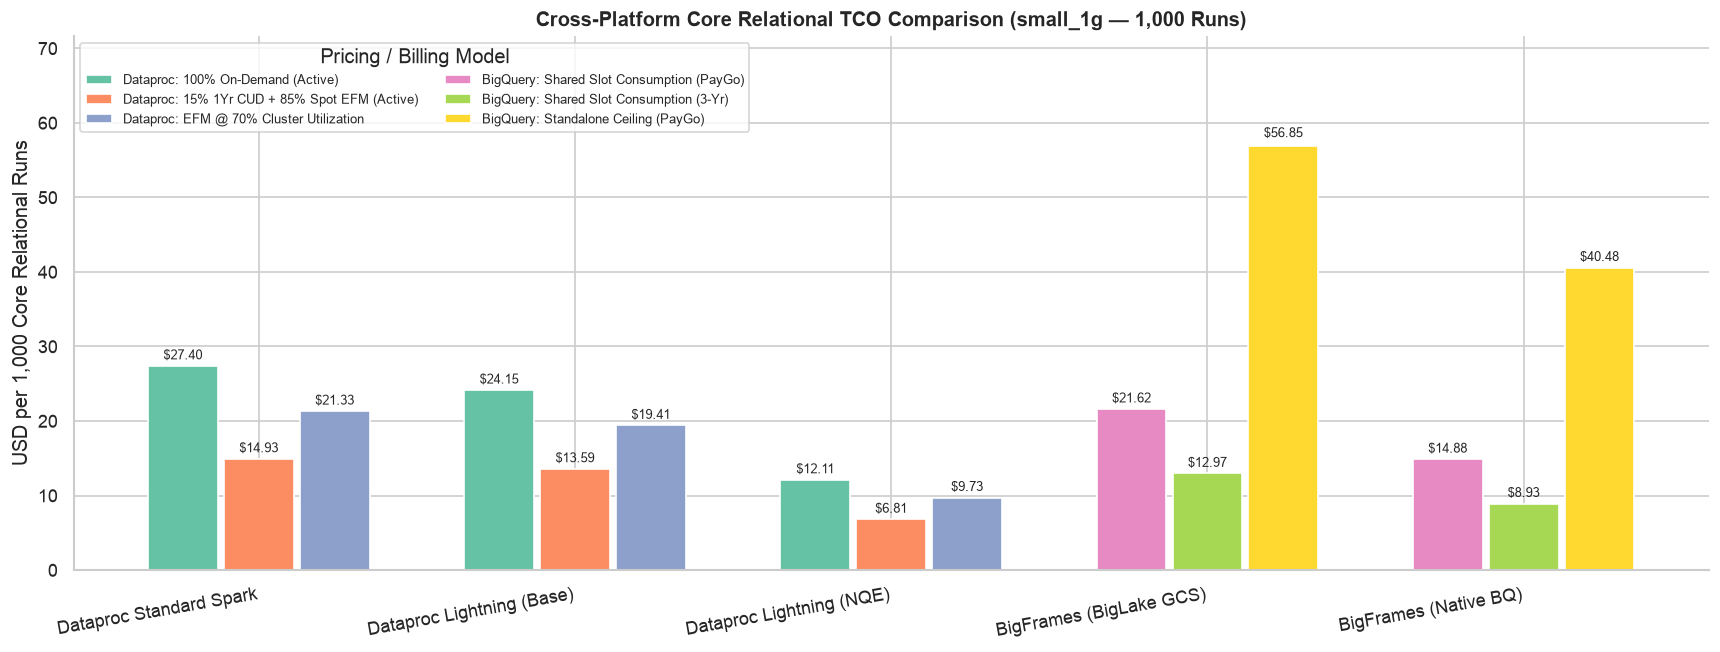


--- Storage Reference Rates (US Multi-Region) ---


,storage_tier,unit_rate,1_tb_monthly_usd,100_tb_monthly_usd,notes
0,"GCS Standard (Open Parquet, US Multi-Region)",$0.026 / GB-month,$26.00 / mo,"$2,600.00 / mo",Zero intra-US egress to us-central1 Dataproc GCE; shared by Spark & BigLake
1,"BigQuery Active Physical Storage (Capacitor, US)",$0.040 / GiB-month,$40.96 / mo,"$4,096.00 / mo",Includes time-travel/fail-safe physical bytes; Capacitor compression reduces bytes scanned
2,"BigQuery Long-Term Physical Storage (90d+ Unchanged, US)",$0.020 / GiB-month,$20.48 / mo,"$2,048.00 / mo",Automatic 50% physical storage discount after 90 days without table mutation


In [9]:
# ==============================================================================
# 8B. PARAMETERIZED TCO MATRIX (DATAPROC BLENDS + CLUSTER LIFETIME + DUAL BQ LENSES)
# ==============================================================================
import math

tco_rows = []
for eng in present_engines:
    eng_df = df[df["engine_variant"] == eng].copy()
    rel_df = eng_df[eng_df["stage_id"].isin(CORE_RELATIONAL_STAGES)]
    rel_sec = float(rel_df["wall_clock_sec"].sum())
    full_sec = float(eng_df["wall_clock_sec"].sum())

    if eng.startswith("spark_"):
        is_lgt = eng != "spark_standard"
        for blend_name in BLEND_WEIGHTS:
            rate = compute_dataproc_hourly_cost(
                blend_name, CLUSTER_TOPOLOGY, PRICING_CONFIG, lightning=is_lgt, include_master=INCLUDE_MASTER_IN_TCO
            )
            # 1) Active Stage Time (100% busy shared cluster)
            rel_cost = rate["total_cluster_hr"] * (rel_sec / 3600.0)
            full_cost = rate["total_cluster_hr"] * (full_sec / 3600.0)
            tco_rows.append({
                "engine_variant": eng,
                "engine_label": ENGINE_LABELS[eng],
                "pricing_tier": blend_name,
                "billing_lens": "Active Stage Time (100% Busy Shared Cluster)",
                "hourly_rate_usd": rate["total_cluster_hr"],
                "rel_cost_per_run_usd": rel_cost,
                "full_cost_per_run_usd": full_cost,
                "rel_cost_1k_runs_usd": rel_cost * 1000.0,
                "full_cost_1k_runs_usd": full_cost * 1000.0,
            })

            # 2) Cluster-Lifetime Sensitivity on highlighted EFM & On-Demand tiers (idle/driver gap + ephemeral spin-up)
            if blend_name in ("100% On-Demand", ACTIVE_CLUSTER_BLEND):
                rel_util_cost = rel_cost / SPARK_CLUSTER_UTILIZATION_SENSITIVITY
                full_util_cost = full_cost / SPARK_CLUSTER_UTILIZATION_SENSITIVITY
                tco_rows.append({
                    "engine_variant": eng,
                    "engine_label": ENGINE_LABELS[eng],
                    "pricing_tier": blend_name,
                    "billing_lens": f"Cluster-Lifetime ({int(SPARK_CLUSTER_UTILIZATION_SENSITIVITY*100)}% Util / Driver Gap)",
                    "hourly_rate_usd": rate["total_cluster_hr"],
                    "rel_cost_per_run_usd": rel_util_cost,
                    "full_cost_per_run_usd": full_util_cost,
                    "rel_cost_1k_runs_usd": rel_util_cost * 1000.0,
                    "full_cost_1k_runs_usd": full_util_cost * 1000.0,
                })

                rel_eph_cost = rate["total_cluster_hr"] * ((rel_sec + SPARK_EPHEMERAL_PROVISION_OVERHEAD_SEC) / 3600.0)
                full_eph_cost = rate["total_cluster_hr"] * ((full_sec + SPARK_EPHEMERAL_PROVISION_OVERHEAD_SEC) / 3600.0)
                tco_rows.append({
                    "engine_variant": eng,
                    "engine_label": ENGINE_LABELS[eng],
                    "pricing_tier": blend_name,
                    "billing_lens": f"Ephemeral Cluster (+{int(SPARK_EPHEMERAL_PROVISION_OVERHEAD_SEC)}s Spin-Up/Down)",
                    "hourly_rate_usd": rate["total_cluster_hr"],
                    "rel_cost_per_run_usd": rel_eph_cost,
                    "full_cost_per_run_usd": full_eph_cost,
                    "rel_cost_1k_runs_usd": rel_eph_cost * 1000.0,
                    "full_cost_1k_runs_usd": full_eph_cost * 1000.0,
                })

        # Worker-only 16-vCPU parity vs telemetry est_list_cost_usd
        w_rate_od = compute_dataproc_hourly_cost(
            "100% On-Demand", CLUSTER_TOPOLOGY, PRICING_CONFIG, lightning=is_lgt, include_master=False
        )
        tco_rows.append({
            "engine_variant": eng,
            "engine_label": ENGINE_LABELS[eng],
            "pricing_tier": f"Worker-Only List Parity ({CLUSTER_TOPOLOGY['worker_vcpus']} vCPUs)",
            "billing_lens": "Matches telemetry est_list_cost_usd",
            "hourly_rate_usd": w_rate_od["total_cluster_hr"],
            "rel_cost_per_run_usd": float(rel_df["est_list_cost_usd"].sum()),
            "full_cost_per_run_usd": float(eng_df["est_list_cost_usd"].sum()),
            "rel_cost_1k_runs_usd": float(rel_df["est_list_cost_usd"].sum()) * 1000.0,
            "full_cost_1k_runs_usd": float(eng_df["est_list_cost_usd"].sum()) * 1000.0,
        })
    else:
        raw_cap = eng_df["bq_slot_cap"].dropna()
        slot_cap = int(raw_cap.iloc[0]) if not raw_cap.empty else None
        rel_slot_hrs = float(rel_df["bq_slot_seconds"].sum()) / 3600.0
        full_slot_hrs = float(eng_df["bq_slot_seconds"].sum()) / 3600.0

        min_sec = PRICING_CONFIG["bq_autoscale_min_bill_sec"]
        slot_inc = int(PRICING_CONFIG["bq_autoscale_increment_slots"])
        # Apply 60s minimum autoscale floor across the contiguous pipeline pass (NOT per stage)
        rel_pass_floored_sec = max(min_sec, rel_sec)
        full_pass_floored_sec = max(min_sec, full_sec)

        # Quantize peak/avg autoscale demand to 50-slot Enterprise increments capped at slot_cap
        rel_avg_slots = float((rel_df["bq_slot_seconds"].sum() / rel_sec)) if rel_sec > 0 else 0.0
        full_avg_slots = float((eng_df["bq_slot_seconds"].sum() / full_sec)) if full_sec > 0 else 0.0
        rel_stepped_slots = min(slot_cap, max(slot_inc, int(math.ceil(rel_avg_slots / slot_inc) * slot_inc))) if slot_cap else None
        full_stepped_slots = min(slot_cap, max(slot_inc, int(math.ceil(full_avg_slots / slot_inc) * slot_inc))) if slot_cap else None

        for tier_name, slot_rate in PRICING_CONFIG["bq_enterprise_slot_hr"].items():
            # Lens (a): Dedicated / Shared Reservation Slot-Hour Consumption (0s idle waste)
            rel_shared = rel_slot_hrs * slot_rate
            full_shared = full_slot_hrs * slot_rate
            tco_rows.append({
                "engine_variant": eng,
                "engine_label": ENGINE_LABELS[eng],
                "pricing_tier": tier_name,
                "billing_lens": "(a) Shared Slot-Hr Consumption (0s idle waste)",
                "hourly_rate_usd": (slot_cap * slot_rate) if slot_cap else np.nan,
                "rel_cost_per_run_usd": rel_shared,
                "full_cost_per_run_usd": full_shared,
                "rel_cost_1k_runs_usd": rel_shared * 1000.0,
                "full_cost_1k_runs_usd": full_shared * 1000.0,
            })

            if slot_cap is not None:
                # Lens (b): Standalone Reservation Ceiling (Actual Contiguous Wall-Clock)
                rel_ceil = slot_cap * (rel_sec / 3600.0) * slot_rate
                full_ceil = slot_cap * (full_sec / 3600.0) * slot_rate
                tco_rows.append({
                    "engine_variant": eng,
                    "engine_label": ENGINE_LABELS[eng],
                    "pricing_tier": tier_name,
                    "billing_lens": f"(b) Standalone {slot_cap}-Slot Ceiling (Wall-Clock)",
                    "hourly_rate_usd": slot_cap * slot_rate,
                    "rel_cost_per_run_usd": rel_ceil,
                    "full_cost_per_run_usd": full_ceil,
                    "rel_cost_1k_runs_usd": rel_ceil * 1000.0,
                    "full_cost_1k_runs_usd": full_ceil * 1000.0,
                })

                # Lens (b*): Contiguous-Pass Autoscale 60s Min-Bill Floor (quantized to 50-slot step vs full ceiling)
                rel_floor_ceil = slot_cap * (rel_pass_floored_sec / 3600.0) * slot_rate
                full_floor_ceil = slot_cap * (full_pass_floored_sec / 3600.0) * slot_rate
                tco_rows.append({
                    "engine_variant": eng,
                    "engine_label": ENGINE_LABELS[eng],
                    "pricing_tier": tier_name,
                    "billing_lens": f"(b*) Contiguous Pass 60s Min-Bill Floor ({slot_cap} slots)",
                    "hourly_rate_usd": slot_cap * slot_rate,
                    "rel_cost_per_run_usd": rel_floor_ceil,
                    "full_cost_per_run_usd": full_floor_ceil,
                    "rel_cost_1k_runs_usd": rel_floor_ceil * 1000.0,
                    "full_cost_1k_runs_usd": full_floor_ceil * 1000.0,
                })

                # Lens (b-step): Contiguous-Pass Autoscale 60s Floor @ 50-slot Enterprise increment
                if rel_stepped_slots and full_stepped_slots:
                    rel_step_cost = rel_stepped_slots * (rel_pass_floored_sec / 3600.0) * slot_rate
                    full_step_cost = full_stepped_slots * (full_pass_floored_sec / 3600.0) * slot_rate
                    tco_rows.append({
                        "engine_variant": eng,
                        "engine_label": ENGINE_LABELS[eng],
                        "pricing_tier": tier_name,
                        "billing_lens": f"(b-step) Autoscale {slot_inc}-Slot Increment + 60s Floor ({rel_stepped_slots}/{full_stepped_slots} slots)",
                        "hourly_rate_usd": rel_stepped_slots * slot_rate,
                        "rel_cost_per_run_usd": rel_step_cost,
                        "full_cost_per_run_usd": full_step_cost,
                        "rel_cost_1k_runs_usd": rel_step_cost * 1000.0,
                        "full_cost_1k_runs_usd": full_step_cost * 1000.0,
                    })

tco_df = pd.DataFrame(tco_rows)
print("--- Full Parameterized TCO Matrix (Per Run & Projected 1,000 Runs/Month) ---")
show_table(
    tco_df.drop(columns=["engine_variant"]),
    {
        "hourly_rate_usd": "${:.4f}/hr",
        "rel_cost_per_run_usd": "${:.5f}",
        "full_cost_per_run_usd": "${:.5f}",
        "rel_cost_1k_runs_usd": "${:,.2f}",
        "full_cost_1k_runs_usd": "${:,.2f}",
    },
)

# Comparative TCO Visual across highlighted realistic production tiers (tight centered bars per engine)
spark_tiers = [
    ("100% On-Demand", "Active Stage Time (100% Busy Shared Cluster)", "Dataproc: 100% On-Demand (Active)", "#66C2A5"),
    (ACTIVE_CLUSTER_BLEND, "Active Stage Time (100% Busy Shared Cluster)", "Dataproc: 15% 1Yr CUD + 85% Spot EFM (Active)", "#FC8D62"),
    (ACTIVE_CLUSTER_BLEND, f"Cluster-Lifetime ({int(SPARK_CLUSTER_UTILIZATION_SENSITIVITY*100)}% Util / Driver Gap)", "Dataproc: EFM @ 70% Cluster Utilization", "#8DA0CB"),
]
bq_paygo_key = next(iter(PRICING_CONFIG["bq_enterprise_slot_hr"]))
bq_3yr_key = list(PRICING_CONFIG["bq_enterprise_slot_hr"])[-1]
bq_tiers = [
    (bq_paygo_key, "(a) Shared Slot-Hr Consumption (0s idle waste)", "BigQuery: Shared Slot Consumption (PayGo)", "#E78AC3"),
    (bq_3yr_key, "(a) Shared Slot-Hr Consumption (0s idle waste)", "BigQuery: Shared Slot Consumption (3-Yr)", "#A6D854"),
    (bq_paygo_key, f"(b) Standalone {CLUSTER_TOPOLOGY['bq_slot_cap']}-Slot Ceiling (Wall-Clock)", "BigQuery: Standalone Ceiling (PayGo)", "#FFD92F"),
]

fig, ax = plt.subplots(figsize=(14.5, 5.6))
x_pos = np.arange(len(present_engines))
bw = 0.24
plotted_labels = set()
max_hl_cost = 0.0

for e_idx, eng in enumerate(present_engines):
    if eng.startswith("spark_"):
        bars_spec = []
        for tier_key, lens_key, legend_lbl, color in spark_tiers:
            match = tco_df[
                (tco_df["engine_variant"] == eng)
                & (tco_df["pricing_tier"] == tier_key)
                & (tco_df["billing_lens"] == lens_key)
            ]
            if not match.empty:
                bars_spec.append((float(match.iloc[0]["rel_cost_1k_runs_usd"]), legend_lbl, color))
    else:
        bars_spec = []
        for tier_key, lens_key, legend_lbl, color in bq_tiers:
            match = tco_df[
                (tco_df["engine_variant"] == eng)
                & (tco_df["pricing_tier"] == tier_key)
                & (tco_df["billing_lens"] == lens_key)
            ]
            if not match.empty:
                bars_spec.append((float(match.iloc[0]["rel_cost_1k_runs_usd"]), legend_lbl, color))

    n_bars = len(bars_spec)
    for b_idx, (val, legend_lbl, color) in enumerate(bars_spec):
        max_hl_cost = max(max_hl_cost, val)
        offset = (b_idx - (n_bars - 1) / 2.0) * bw
        lbl = legend_lbl if legend_lbl not in plotted_labels else None
        plotted_labels.add(legend_lbl)
        bar = ax.bar(x_pos[e_idx] + offset, val, width=bw * 0.92, color=color, edgecolor="white", label=lbl)
        ax.text(
            bar[0].get_x() + bar[0].get_width() / 2.0,
            val + max(0.5, val * 0.015),
            f"${val:.2f}",
            ha="center",
            va="bottom",
            fontsize=8,
        )

ax.set_xticks(x_pos)
ax.set_xticklabels([ENGINE_LABELS[e] for e in present_engines], rotation=10, ha="right")
ax.set_ylabel("USD per 1,000 Core Relational Runs")
ax.set_title(f"Cross-Platform Core Relational TCO Comparison ({ACTIVE_SCALE_PRESET} — 1,000 Runs)")
ax.set_ylim(0, max(1.0, max_hl_cost) * 1.26)
ax.legend(title="Pricing / Billing Model", fontsize=8, ncol=2, loc="upper left", frameon=True)
plt.tight_layout()
plt.show()

# Storage reference table (US multi-region)
storage_ref_df = pd.DataFrame([
    {
        "storage_tier": "GCS Standard (Open Parquet, US Multi-Region)",
        "unit_rate": f"${PRICING_CONFIG['storage_monthly_usd']['gcs_standard_per_gb']:.3f} / GB-month",
        "1_tb_monthly_usd": PRICING_CONFIG["storage_monthly_usd"]["gcs_standard_per_gb"] * 1000.0,
        "100_tb_monthly_usd": PRICING_CONFIG["storage_monthly_usd"]["gcs_standard_per_gb"] * 100_000.0,
        "notes": "Zero intra-US egress to us-central1 Dataproc GCE; shared by Spark & BigLake",
    },
    {
        "storage_tier": "BigQuery Active Physical Storage (Capacitor, US)",
        "unit_rate": f"${PRICING_CONFIG['storage_monthly_usd']['bq_active_physical_per_gib']:.3f} / GiB-month",
        "1_tb_monthly_usd": PRICING_CONFIG["storage_monthly_usd"]["bq_active_physical_per_gib"] * 1024.0,
        "100_tb_monthly_usd": PRICING_CONFIG["storage_monthly_usd"]["bq_active_physical_per_gib"] * 1024.0 * 100.0,
        "notes": "Includes time-travel/fail-safe physical bytes; Capacitor compression reduces bytes scanned",
    },
    {
        "storage_tier": "BigQuery Long-Term Physical Storage (90d+ Unchanged, US)",
        "unit_rate": f"${PRICING_CONFIG['storage_monthly_usd']['bq_long_term_physical_per_gib']:.3f} / GiB-month",
        "1_tb_monthly_usd": PRICING_CONFIG["storage_monthly_usd"]["bq_long_term_physical_per_gib"] * 1024.0,
        "100_tb_monthly_usd": PRICING_CONFIG["storage_monthly_usd"]["bq_long_term_physical_per_gib"] * 1024.0 * 100.0,
        "notes": "Automatic 50% physical storage discount after 90 days without table mutation",
    },
])
print("\n--- Storage Reference Rates (US Multi-Region) ---")
show_table(
    storage_ref_df,
    {
        "1_tb_monthly_usd": "${:,.2f} / mo",
        "100_tb_monthly_usd": "${:,.2f} / mo",
    },
)


In [10]:
# ==============================================================================
# 9. CONDITIONAL DYNAMIC EXECUTIVE SUMMARY & SCALE-UP GUIDANCE
# ==============================================================================
rel_totals = df[df["stage_id"].isin(CORE_RELATIONAL_STAGES)].groupby("engine_variant")["wall_clock_sec"].sum()
fastest_rel_eng = rel_totals.idxmin()
fastest_rel_sec = float(rel_totals.min())

print(f"EXECUTIVE BENCHMARK SUMMARY ({PROVENANCE} | scale={ACTIVE_SCALE_PRESET})")
print("-" * 86)

if parity_overall_pass:
    print(f"1. Correctness Parity    : PASS across {len(present_engines)} engines & {len(present_stages)} stages (0 row drift, <= {PARITY_TOLERANCE_PCT}% checksum tol).")
else:
    print(f"1. Correctness Parity    : FAIL — {len(failed_checks)} stage-engine check(s) exceeded tolerance or row count parity!")

print(f"2. Fastest Relational    : {ENGINE_LABELS[fastest_rel_eng]} ({fastest_rel_sec:.2f}s across Stages 1+2A+3; note timer boundary differences).")

if {"spark_standard", "spark_lightning_nqe"}.issubset(set(rel_totals.index)):
    std_s = float(rel_totals["spark_standard"])
    nqe_s = float(rel_totals["spark_lightning_nqe"])
    nqe_speedup = ((std_s / nqe_s) - 1.0) * 100.0
    efm_row = breakeven_df[breakeven_df["cluster_blend"] == ACTIVE_CLUSTER_BLEND].iloc[0]
    req_sp = float(efm_row["req_breakeven_speedup_pct"])
    net_delta = float(efm_row["nqe_net_cost_delta_pct"])
    if net_delta < 0:
        be_phrase = f"exceeding the {req_sp:+.2f}% EFM break-even threshold (net {net_delta:+.1f}% compute cost delta)"
    elif nqe_speedup > 0:
        be_phrase = f"faster than Standard, but trailing the {req_sp:+.2f}% EFM break-even threshold (net {net_delta:+.1f}% compute cost delta)"
    else:
        be_phrase = f"slower than Standard Spark, failing the {req_sp:+.2f}% EFM break-even threshold (net {net_delta:+.1f}% compute cost delta)"
    print(f"3. Lightning NQE Impact  : {std_s / nqe_s:.2f}x ({nqe_speedup:+.1f}% speedup vs Standard Spark), {be_phrase}.")

if {"bigframes_biglake_gcs", "bigframes_native_bq"}.issubset(set(present_engines)):
    s1_bl = df.loc[(df["engine_variant"] == "bigframes_biglake_gcs") & (df["stage_id"] == "stage1_bronze_to_silver"), "bq_total_slot_ms"]
    s1_nv = df.loc[(df["engine_variant"] == "bigframes_native_bq") & (df["stage_id"] == "stage1_bronze_to_silver"), "bq_total_slot_ms"]
    bl_ms = float(df.loc[(df["engine_variant"] == "bigframes_biglake_gcs") & (df["stage_id"].isin(CORE_RELATIONAL_STAGES)), "bq_total_slot_ms"].sum())
    nv_ms = float(df.loc[(df["engine_variant"] == "bigframes_native_bq") & (df["stage_id"].isin(CORE_RELATIONAL_STAGES)), "bq_total_slot_ms"].sum())
    s1_msg = ""
    if not s1_bl.empty and not s1_nv.empty and float(s1_bl.iloc[0]) > 0:
        s1_delta = (1.0 - float(s1_nv.iloc[0]) / float(s1_bl.iloc[0])) * 100.0
        s1_verb = "reduces" if s1_delta >= 0 else "increases"
        s1_msg = f"Stage 1 Bronze {s1_verb} slot-ms by {abs(s1_delta):.1f}% ({float(s1_bl.iloc[0])/1000:.1f} -> {float(s1_nv.iloc[0])/1000:.1f} slot-s); "
    rel_delta = (1.0 - nv_ms / bl_ms) * 100.0 if bl_ms > 0 else 0.0
    rel_verb = "reduction" if rel_delta >= 0 else "increase"
    print(
        f"4. Capacitor vs BigLake  : {s1_msg}overall relational pass {rel_verb} of {abs(rel_delta):.1f}% "
        f"({bl_ms/1000:.1f} -> {nv_ms/1000:.1f} slot-s; Stages 2A/3 use native BQ Silver in both)."
    )

if "spark_standard" in present_engines and ("bigframes_biglake_gcs" in present_engines or "bigframes_native_bq" in present_engines):
    parts = []
    if "bigframes_biglake_gcs" in present_engines:
        s1_sp = float(df.loc[(df["engine_variant"] == "spark_standard") & (df["stage_id"] == "stage1_bronze_to_silver"), "vcpu_seconds"].sum())
        s1_bq = float(df.loc[(df["engine_variant"] == "bigframes_biglake_gcs") & (df["stage_id"] == "stage1_bronze_to_silver"), "bq_slot_seconds"].sum())
        if s1_bq > 0:
            parts.append(f"Stage 1 identical GCS Parquet: 1 Consumed BQ Slot ≈ {s1_sp / s1_bq:.2f} Provisioned Spark vCPUs")
    if "bigframes_native_bq" in present_engines:
        sp_vcpu_s = float(df.loc[(df["engine_variant"] == "spark_standard") & (df["stage_id"].isin(CORE_RELATIONAL_STAGES)), "vcpu_seconds"].sum())
        nv_slot_s = float(df.loc[(df["engine_variant"] == "bigframes_native_bq") & (df["stage_id"].isin(CORE_RELATIONAL_STAGES)), "bq_slot_seconds"].sum())
        if nv_slot_s > 0:
            parts.append(f"Stages 1+2A+3 vs Native BQ: 1 Consumed BQ Slot ≈ {sp_vcpu_s / nv_slot_s:.2f} Provisioned Spark vCPUs")
    print(f"5. Compute Equivalency   : {'; '.join(parts)}.")

if not udf_df.empty:
    if "spark_lightning_nqe" in set(udf_df["engine_variant"]):
        nqe_udf = udf_df[udf_df["engine_variant"] == "spark_lightning_nqe"].iloc[0]
        factor = float(nqe_udf["udf_slowdown_factor"])
        note = str(nqe_udf["nqe_fallback_note"]).strip()
        if factor > 1.0:
            note_desc = f" ({note})" if note else ""
            print(
                f"6. Python UDF Penalty    : Stage 2B scalar @F.udf is {factor:.1f}x slower than Stage 2A on NQE{note_desc}; "
                "prefer native Catalyst/Velox expressions or BigFrames SQL pushdown."
            )
        else:
            print(f"6. Python UDF Impact     : Stage 2B ran at {factor:.2f}x of Stage 2A on NQE ({note or 'no fallback recorded'}).")
    else:
        max_row = udf_df.sort_values("udf_slowdown_factor", ascending=False).iloc[0]
        print(f"6. Python UDF Impact     : Max Stage 2B vs 2A factor = {max_row['udf_slowdown_factor']:.1f}x on {max_row['engine_variant']}.")

print("7. Scale-Up Note         : Set SCALE_PRESET='medium_100g' or 'large_500g' in .env and re-run 00-03; ")
print("                           contiguous passes >60s eliminate BigQuery's 60s autoscale minimum floor overhead.")


EXECUTIVE BENCHMARK SUMMARY (OFFLINE SAMPLE TELEMETRY (DRY-RUN DATA) | scale=small_1g)
--------------------------------------------------------------------------------------
1. Correctness Parity    : PASS across 5 engines & 4 stages (0 row drift, <= 0.01% checksum tol).
2. Fastest Relational    : BigFrames (Native BQ) (24.29s across Stages 1+2A+3; note timer boundary differences).
3. Lightning NQE Impact  : 2.35x (+135.4% speedup vs Standard Spark), exceeding the +7.44% EFM break-even threshold (net -54.4% compute cost delta).
4. Capacitor vs BigLake  : Stage 1 Bronze reduces slot-ms by 34.1% (512.6 -> 337.7 slot-s); overall relational pass reduction of 31.2% (1297.0 -> 892.7 slot-s; Stages 2A/3 use native BQ Silver in both).
5. Compute Equivalency   : Stage 1 identical GCS Parquet: 1 Consumed BQ Slot ≈ 0.89 Provisioned Spark vCPUs; Stages 1+2A+3 vs Native BQ: 1 Consumed BQ Slot ≈ 1.43 Provisioned Spark vCPUs.
6. Python UDF Penalty    : Stage 2B scalar @F.udf is 12.6x slower than Stag